# Data Mining project: analysis of the `health` data

* Group: Group 10

This notebook starts from the cleaned files (`data/health_clean/`) and follows the order of the courses.

*Use of generative AI: this work was done with the help of Claude (Anthropic). The assistant wrote most of the code and texts, and proposed methods and interpretation leads. On our side, we chose the steps, discussed and validated every cleaning and analysis decision, reviewed the results, and asked for corrections when a figure or an interpretation did not hold.*

## Course 1: Understanding your data

### 1.1 Analysis tables

14 measurements are taken at every encounter, 18 only once per patient. We therefore work on two tables: one per encounter (1,067 rows) and one per patient (240 rows, with the median of the repeated measurements).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
D = Path("../data/health_clean")

P = pd.read_csv(D / "patient_administration.csv", parse_dates=["date_of_birth"])
E = pd.read_csv(D / "clinical_encounters.csv", parse_dates=["encounter_start", "encounter_end"])
O = pd.read_csv(D / "clinical_observations.csv")
PR = pd.read_csv(D / "clinical_procedures.csv")
W = pd.read_csv(D / "observations_wide.csv", parse_dates=["encounter_start"])
CAT = pd.read_csv(D / "observation_catalog.csv").set_index("observation_code")

REPEATED = CAT.index[(CAT["n_measures"] > 241) & (CAT["type"] == "number")].tolist()
SINGLE = CAT.index[(CAT["n_measures"] <= 241) & (CAT["type"] == "number")].tolist()

visits = W.merge(P[["patient_number", "date_of_birth"]], on="patient_number")
visits["AGE"] = (visits["encounter_start"] - visits["date_of_birth"]).dt.days / 365.25
visits = visits[["encounter_number", "patient_number"] + REPEATED + ["AGE"]]

ordinal = {"none": 0, "mild": 1, "moderate": 2, "severe": 3}
patient = (O[O["observation_code"].isin(SINGLE)].pivot(index="patient_number", columns="observation_code", values="numeric_value")
           .join(O[O["observation_code"].isin(["MUSC", "NEURO"])]
                 .pivot(index="patient_number", columns="observation_code", values="text_value").apply(lambda c: c.map(ordinal)))
           .join(visits.groupby("patient_number")[REPEATED + ["AGE"]].median()))
print("per encounter:", visits.shape, "| per patient:", patient.shape)

per encounter: (1067, 16) | per patient: (240, 30)


### 1.2 Variable types

* Continuous numeric: the measurements (pulse, ages, scores…); discrete: `AGECOND` (number of conditions).
* Ordered nominal: `MUSC`, `NEURO` (none < mild < moderate < severe), treated as numbers from 0 to 3; confidentiality (standard < confidential < restricted).
* Unordered nominal: sex, region, occupation, encounter type, clinic, procedure, `OCULAR`, `VESTIB`, `BINOCOORD`.
* Dates and notes will be handled in courses 5 and 6.

### 1.3 Numeric variables

For each measurement: mean and standard deviation, median with min, max and quartiles. The "shape" column summarises the histogram without displaying it.

In [2]:
variables = {c: visits[c] for c in REPEATED} | {c: patient[c] for c in SINGLE}

def shape(s):
    s = s.dropna()
    if max((s == s.min()).mean(), (s == s.max()).mean()) > 0.03:
        return "stuck at a limit"
    if abs(s.skew()) < 0.5:
        return "symmetric"
    return "stretched downwards" if s.skew() < 0 else "stretched upwards"

stats = pd.DataFrame({c: {"name": CAT.loc[c, "name"], "mean": s.mean(), "std": s.std(), "median": s.median(),
                          "min": s.min(), "Q1": s.quantile(.25), "Q3": s.quantile(.75), "max": s.max(), "shape": shape(s)}
                      for c, s in variables.items()}).T
with pd.option_context("display.float_format", "{:.2f}".format, "display.max_rows", 40):
    display(stats.sort_values("shape"))

,name,mean,std,median,min,Q1,Q3,max,shape
LEFTEYE,Left-eye deviation,-2.09,4.38,-1.40,-17.60,-3.80,0.70,6.90,stretched downwards
CARDOUT,Estimated cardiac output,5.47,1.01,5.38,3.00,4.80,6.07,9.60,stretched upwards
LATSWAY,Lateral sway index,33.35,18.47,31.35,0.00,21.30,42.50,94.40,stretched upwards
RIGHTEYE,Right-eye deviation,2.26,4.23,1.10,-4.50,-0.70,4.10,20.00,stretched upwards
THORVIB,Thoracic vibration index,30.25,15.89,28.50,0.00,19.50,39.10,97.30,stretched upwards
AGECOND,Age-related condition count,0.98,0.91,1.00,0.00,0.00,2.00,4.00,stuck at a limit
BALANCE,Balance score,76.40,12.96,76.80,38.90,67.90,85.20,100.00,stuck at a limit
COGNITIVE,Cognitive score,86.32,8.59,87.10,57.20,81.20,92.60,100.00,stuck at a limit
THERMQUAL,Thermal detection quality,89.40,7.50,90.25,58.20,85.55,95.08,100.00,stuck at a limit
THORPEAK,Thoracic secondary peak index,28.74,17.90,26.85,0.00,15.50,40.00,85.40,stuck at a limit


* Most physiological measurements are symmetric (close to a normal distribution).
* Many scores are capped at 100 (balance, cognition, camera, identity…): these variables are truncated.
* `IDCONS` and `CAMMATCH` are almost always high, with a few very low patients. `BIOAGE` goes down to 11 years while all patients are at least 15.

### 1.4 Nominal variables

In [3]:
nominal = {
    "sex": P["registered_sex"], "region": P["home_region"],
    "detailed occupation": P["occupation_detailed"], "clinic": P["primary_facility_license"],
    "referred by": E["referral_source"], "confidentiality": E["confidentiality_class"], "procedure type": PR["procedure_code"],
} | {c: O.loc[O["observation_code"] == c, "text_value"] for c in ["OCULAR", "VESTIB", "BINOCOORD"]}

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame([{"variable": name, "distribution": ", ".join(f"{k} ({v})" for k, v in s.value_counts().items())}
                          for name, s in nominal.items()]))

,variable,distribution
0,sex,"female (96), male (93), nonbinary (51)"
1,region,"Avelora Federation (54), Nordhaven Union (52), Valenne Republic (48), Kintara Republic (47), Tembara Commonwealth (39)"
2,detailed occupation,"False (187), True (53)"
3,clinic,"FAC-VLN-101 (150), FAC-AVL-201 (64), FAC-AVL-301 (26)"
4,referred by,"executive health office (226), self (217), research programme (213), primary care (205), occupational service (203)"
5,confidentiality,"standard (581), confidential (295), restricted (191)"
6,procedure type,"OCT-TRK (51), MRP-42 (50), OCC-PNL (49), AUT-REV (43), CARD-IMG (41), AGE-PNL (39), MOB-PNL (37)"
7,OCULAR,"inconclusive (455), normal (413), atypical (42)"
8,VESTIB,"normal (169), inconclusive (60), abnormal (11)"
9,BINOCOORD,"normal (148), reduced (78), atypical (14)"


Patients are well distributed between sexes and regions. The five referral origins are equal (~210 each): the "executive health office", reserved for executives, is as frequent as the attending physician. Nearly half of the encounters are confidential or restricted.

### 1.5 Correlations: Pearson and Spearman

* Pearson measures a straight-line relationship and is sensitive to extreme values.
* Spearman works on ranks: it detects any relationship that goes up or down, and extreme points influence it little.

We compare the two on the encounter measurements. A difference between the two maps signals a relationship carried by a few points.

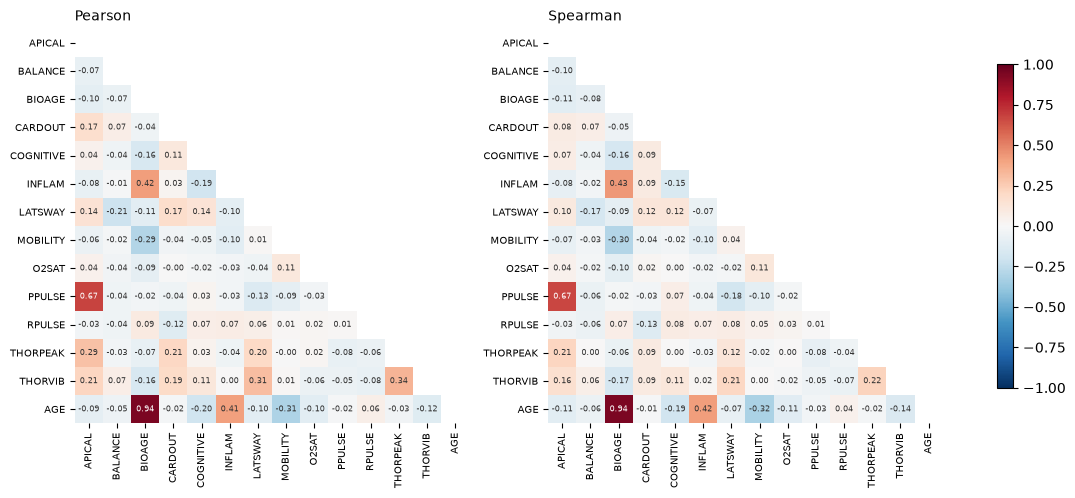

In [4]:
def heatmap(corr, title, ax):
    mask = np.triu(np.ones_like(corr, dtype=bool))
    im = ax.imshow(corr.mask(mask), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(corr)), corr.index, fontsize=7)
    for i in range(len(corr)):
        for j in range(i):
            v = corr.iat[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(v) > .6 else "#333")
    ax.set_title(title, fontsize=10, loc="left")
    for side in ax.spines.values():
        side.set_visible(False)
    return im

num = visits[REPEATED + ["AGE"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
heatmap(num.corr("pearson"), "Pearson", axes[0])
im = heatmap(num.corr("spearman"), "Spearman", axes[1])
fig.colorbar(im, ax=axes, shrink=.7)
plt.show()

At the patient level (30 variables), a map would be unreadable. We therefore only list the most strongly related pairs, then those where the two coefficients differ most.

In [5]:
def pairs(tab, level):
    s, p = tab.corr("spearman"), tab.corr("pearson")
    return pd.DataFrame([(level, a, b, p.loc[a, b], s.loc[a, b])
                         for i, a in enumerate(tab.columns) for b in tab.columns[i + 1:]],
                        columns=["level", "variable 1", "variable 2", "pearson", "spearman"])

all_pairs = pd.concat([pairs(num, "encounter"), pairs(patient, "patient")])
all_pairs["gap"] = all_pairs["pearson"] - all_pairs["spearman"]
display(all_pairs[all_pairs["spearman"].abs() >= .35].sort_values("spearman", key=abs, ascending=False).round(2))
display(all_pairs.sort_values("gap", key=abs, ascending=False).head(5).round(2))

,level,variable 1,variable 2,pearson,spearman,gap
379,patient,BIOAGE,AGE,0.95,0.95,-0.00
35,encounter,BIOAGE,AGE,0.94,0.94,-0.00
352,patient,APICAL,PPULSE,0.76,0.75,0.00
308,patient,WALKSPD,MOBILITY,0.73,0.71,0.02
8,encounter,APICAL,PPULSE,0.67,0.67,0.00
371,patient,BIOAGE,INFLAM,0.43,0.45,-0.01
406,patient,INFLAM,AGE,0.43,0.44,-0.01
27,encounter,BIOAGE,INFLAM,0.42,0.43,-0.01
28,patient,AGECOND,AGE,0.42,0.42,-0.01
17,patient,AGECOND,BIOAGE,0.41,0.42,-0.01


,level,variable 1,variable 2,pearson,spearman,gap
32,patient,CAMMATCH,IDCONS,0.46,0.18,0.28
148,patient,IDCONS,CARDOUT,-0.29,-0.11,-0.18
157,patient,IDCONS,THORVIB,-0.27,-0.09,-0.17
46,patient,CAMMATCH,CARDOUT,-0.22,-0.08,-0.14
432,patient,THORPEAK,THORVIB,0.31,0.18,0.13


* The only strong links are expected: biological age / actual age (0.95), heart / wrist pulse (0.75), walking speed / mobility (0.71). All other measurements are almost independent.
* For camera / identity, Pearson is 0.46 but Spearman only 0.18. The link is therefore carried by a few patients who have both values very low, not by the whole population.

### 1.6 Extended sweep: nearly 90 variables per patient

To miss nothing, we build nearly 90 variables per patient from all the files:
* for each measurement: its median, its variability from one visit to the next (standard deviation) and its evolution over time (slope per year);
* anomaly counts: "discordant" pulse, atypical eye tracking, out-of-norm values…;
* encounters (number, duration, confidentiality, types, origin), procedures by type, cardiac recordings and notes.

We then compute Pearson and Spearman on all the pairs (about 3,700) and only keep the strongest ones. We discard the obvious pairs, such as a measurement and its own variability.

In [6]:
PR = pd.read_csv(D / "clinical_procedures.csv")
CR = pd.read_csv(D / "cardiac_recordings.csv")
N = pd.read_csv(D / "clinical_notes.csv")

W2 = visits.merge(W[["encounter_number", "encounter_start"]], on="encounter_number")
W2["AGE_GAP"] = W2["BIOAGE"] - W2["AGE"]
W2["PULSE_GAP"] = W2["APICAL"] - W2["PPULSE"]
W2["T"] = (W2["encounter_start"] - pd.Timestamp("2014-01-01")).dt.days / 365.25
W2 = W2.sort_values(["patient_number", "encounter_start"])
g = W2.groupby("patient_number")

def slope(d, col):
    d = d[["T", col]].dropna()
    return np.polyfit(d["T"], d[col], 1)[0] if len(d) >= 3 else np.nan

feat = g[REPEATED + ["AGE", "AGE_GAP", "PULSE_GAP"]].median()
feat = feat.join(g[REPEATED + ["PULSE_GAP"]].std().add_suffix("_STD"))
for c in ["BIOAGE", "INFLAM", "MOBILITY", "COGNITIVE", "LATSWAY", "THORPEAK", "PULSE_GAP", "CARDOUT"]:
    feat[c + "_SLOPE"] = g.apply(lambda d: slope(d, c))
with_age = W2.dropna(subset=["AGE_GAP"])
feat["MAX_AGE_DROP"] = with_age.groupby("patient_number")["AGE_GAP"].diff().groupby(with_age["patient_number"]).min()
feat = feat.join(patient[SINGLE + ["MUSC", "NEURO"]])

txt = O[O["text_value"].notna()]
count_where = lambda mask: O[mask].groupby("patient_number").size()
feat["N_OCULAR_ATYP"] = count_where((O["observation_code"] == "OCULAR") & (O["text_value"] == "atypical"))
feat["BINOCOORD_ATYP"] = count_where((O["observation_code"] == "BINOCOORD") & (O["text_value"] == "atypical"))
feat["VESTIB_ABNORMAL"] = count_where((O["observation_code"] == "VESTIB") & (O["text_value"] == "abnormal"))
feat["N_DISCORDANT"] = count_where(O["interpretation_code"] == "discordant")
feat["N_REVIEW"] = count_where(O["interpretation_code"] == "review")
feat["N_OUT_OF_RANGE"] = count_where(O["out_of_ref_range"])

E["duration"] = (E["encounter_end"] - E["encounter_start"]).dt.total_seconds() / 60
ge = E.groupby("patient_number")
feat["N_VISITS"] = ge.size()
feat["MEAN_DURATION"] = ge["duration"].mean()
feat["CONFIDENTIAL_SHARE"] = ge["confidentiality_class"].apply(lambda s: (s != "standard").mean())
for t in E["encounter_type"].unique():
    feat["VISIT_" + t] = E[E["encounter_type"] == t].groupby("patient_number").size()
for r in E["referral_source"].dropna().unique():
    feat["REFERRED_" + r.replace(" ", "_")] = E[E["referral_source"] == r].groupby("patient_number").size()
for c in PR["procedure_code"].unique():
    feat["PROC_" + c] = PR[PR["procedure_code"] == c].groupby("patient_number").size()
feat["N_ECG"] = CR.groupby("patient_number").size()
feat["N_NOTES"] = N.groupby("patient_number").size()
comptes = [c for c in feat.columns if c.startswith(("N_", "VISIT_", "REFERRED_", "PROC_", "BINOCOORD_", "VESTIB_"))]
feat[comptes] = feat[comptes].fillna(0)
print("variables per patient:", feat.shape[1])

s, p = feat.corr("spearman"), feat.corr("pearson")
root = lambda v: v.split("_")[0]
sweep = pd.DataFrame([(a, b, p.loc[a, b], s.loc[a, b]) for i, a in enumerate(feat.columns) for b in feat.columns[i + 1:]
                         if root(a) != root(b)], columns=["variable 1", "variable 2", "pearson", "spearman"]).dropna()
sweep["gap"] = sweep["pearson"] - sweep["spearman"]
print("pairs tested:", len(sweep))
display(sweep.sort_values("spearman", key=abs, ascending=False).head(15).round(2))
display(sweep.sort_values("gap", key=abs, ascending=False).head(6).round(2))

variables per patient: 88


pairs tested: 3700


,variable 1,variable 2,pearson,spearman,gap
181,BIOAGE,AGE,0.95,0.95,-0.00
3304,BINOCOORD_ATYP,VISIT_ocular_assessment,0.67,0.81,-0.14
3632,VISIT_research_procedure,PROC_MRP-42,0.33,0.80,-0.47
3359,N_DISCORDANT,VISIT_cardiac_assessment,0.69,0.75,-0.07
8,APICAL,PPULSE,0.76,0.75,0.00
3332,VESTIB_ABNORMAL,VISIT_mobility_assessment,0.89,0.72,0.17
618,MOBILITY,WALKSPD,0.73,0.71,0.02
1431,BIOAGE_STD,N_VISITS,0.68,0.69,-0.01
3269,N_OCULAR_ATYP,BINOCOORD_ATYP,0.67,0.68,-0.01
3275,N_OCULAR_ATYP,VISIT_ocular_assessment,0.57,0.65,-0.09


,variable 1,variable 2,pearson,spearman,gap
3632,VISIT_research_procedure,PROC_MRP-42,0.33,0.80,-0.47
3659,REFERRED_executive_health_office,PROC_MRP-42,0.58,0.14,0.44
3461,MEAN_DURATION,VISIT_specialist_procedure,0.73,0.31,0.42
1408,BIOAGE_STD,MAX_AGE_DROP,-0.65,-0.23,-0.42
2601,MAX_AGE_DROP,VISIT_executive_health_review,-0.87,-0.45,-0.42
3465,MEAN_DURATION,REFERRED_executive_health_office,0.42,0.02,0.40


Beyond the expected links, the sweep brings out two things:
* Anomalies go with targeted examinations. Atypical eye coordination and eye assessments (0.81), discordant pulses and cardiac assessments (0.75), abnormal balance test and mobility assessments (0.72). Some patients are therefore closely followed precisely for these anomalies.
* Sudden drops in biological age from one visit to the next (`MAX_AGE_DROP`) go with the number of "executive health reviews" (Pearson −0.87, but Spearman −0.45). So it is again the doing of a few patients. The "procedure" and "research" encounters go with the `MRP-42` procedure. We look at this procedure more closely.

### 1.7 Zoom on the `MRP-42` procedure

In [7]:
feat["N_MRP42"] = feat["PROC_MRP-42"]
group = feat["N_MRP42"].map(lambda n: "0 doses" if n == 0 else ("1 dose" if n == 1 else "3 or more doses"))
mrp = PR[PR["procedure_code"] == "MRP-42"].join(feat["N_MRP42"], on="patient_number")
display(pd.crosstab(mrp["N_MRP42"].map(lambda n: "1 dose" if n == 1 else "3 or more doses"), mrp["authorization_class"]))
display(feat.groupby(group)[["AGE_GAP", "BIOAGE_SLOPE", "N_VISITS", "MEAN_DURATION", "AGE"]].median().round(2)
        .assign(patients=group.value_counts()))
display(feat.loc[feat["N_MRP42"] >= 3, ["N_MRP42", "AGE", "AGE_GAP", "BIOAGE_SLOPE"]].round(1)
        .join(P.set_index("patient_number")["occupation_text"]).sort_values("AGE_GAP"))

authorization_class,research_restricted,restricted_specialist
N_MRP42,,
1 dose,20,0
3 or more doses,0,30


,AGE_GAP,BIOAGE_SLOPE,N_VISITS,MEAN_DURATION,AGE,patients
N_MRP42,,,,,,
0 doses,-1.26,1.00,4.0,80.83,49.08,212
1 dose,-0.50,1.00,5.0,104.75,46.93,20
3 or more doses,-11.68,-0.88,9.0,149.23,71.36,8


,N_MRP42,AGE,AGE_GAP,BIOAGE_SLOPE,occupation_text
patient_number,,,,,
PAT-31119,4.0,69.8,-14.1,-0.9,Chief executive of Solvane Energy Group
PAT-31044,4.0,66.5,-12.5,0.3,Senior minister of the Avelora Federation
PAT-31074,4.0,73.6,-12.4,-0.9,Executive chair of Nivren Maritime Logistics
PAT-31183,3.0,60.3,-12.0,-0.9,Executive director of Ardena Capital Union
PAT-31174,4.0,75.7,-11.4,-0.2,Regional governor in the Tembara Commonwealth
PAT-31142,3.0,69.0,-10.9,-0.9,Chair of Belen Agro-Industries
PAT-31221,5.0,72.9,-10.6,0.2,Head of government of Kintara Republic
PAT-31099,3.0,80.9,-8.9,-1.0,Retired political intermediary and former coun...


* 8 patients received 3 to 5 doses, all classified "restricted specialist". They are all executives (head of government, minister, governor, CEOs…). Their biological age is about 10 to 12 years lower than their actual age, and it decreases over time: the median slope is negative, whereas it is +1 year per year in all the others.
* 20 ordinary patients received a single dose, classified "restricted research", with no visible effect.

The product is administered repeatedly to an elite that rejuvenates biologically. In parallel, single "research" doses are given to ordinary patients; we will see in course 5 that they arrive after the executives' doses and have no effect. This is only a correlation, but it is the strongest lead.

### 1.8 Shape of the relationships

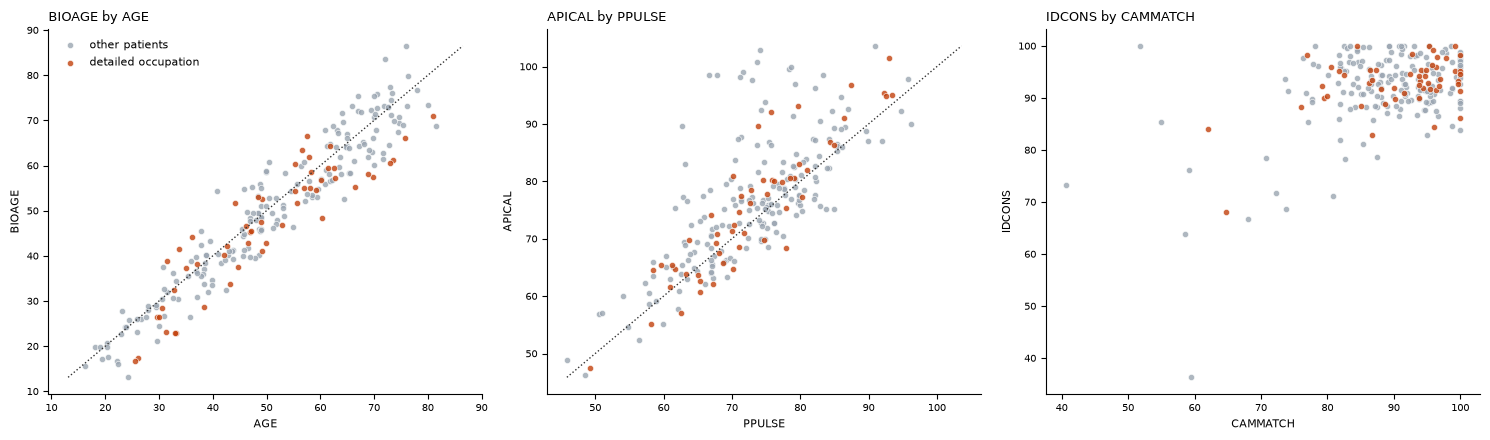

In [8]:
detail = P.set_index("patient_number")["occupation_detailed"].reindex(patient.index)
couples = [("AGE", "BIOAGE", True), ("PPULSE", "APICAL", True), ("CAMMATCH", "IDCONS", False)]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (x, y, diagonale) in zip(axes, couples):
    for grp, couleur, label in [(False, "#9aa5b1", "other patients"), (True, "#c2410c", "detailed occupation")]:
        m = detail == grp
        ax.scatter(patient.loc[m, x], patient.loc[m, y], s=20, color=couleur, alpha=.8, edgecolor="white", linewidth=.5, label=label)
    if diagonale:
        lim = [patient[[x, y]].min().min(), patient[[x, y]].max().max()]
        ax.plot(lim, lim, color="#333", linewidth=1, linestyle=":")
    ax.set_xlabel(x, fontsize=8); ax.set_ylabel(y, fontsize=8); ax.tick_params(labelsize=7)
    ax.set_title(f"{y} by {x}", fontsize=9, loc="left")
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[0].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

* Biological age / actual age: linear relationship, with a few patients clearly below the diagonal.
* Heart / wrist pulse: linear, but about ten patients have a heart that beats 25 to 30 more times per minute than at the wrist.
* Camera / identity: no overall trend, only a few isolated patients at the bottom left.

### 1.9 Summary

Two leads: the `MRP-42` procedure in executives who rejuvenate, and a few patients with strange measurements (pulse, eyes, identity). In both cases, the links come from few patients, which is why Spearman and Pearson do not always agree. At this stage, these are only correlations.

## Course 2: Ordering and grouping your data

Goal: see whether the atypical patients stand out on their own, without telling the algorithms whom to look for.

### 2.1 Choice of variables and scaling

We only keep the 27 medical measurements. The repeated variables are replaced by their gap: `AGE_GAP` replaces biological age, and `PULSE_GAP` replaces the heart pulse. We leave aside the procedures, the occupation and the anomaly counts: they serve to interpret the groups, not to form them, otherwise we would necessarily find what we put in.

Since the units are very different, we standardise each variable (mean 0, standard deviation 1). We then measure the similarity between patients by the Euclidean distance.

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

MEDICAL = ["PPULSE", "PULSE_GAP", "RPULSE", "AGE_GAP", "BALANCE", "CARDOUT", "COGNITIVE", "INFLAM", "LATSWAY",
           "MOBILITY", "O2SAT", "THORPEAK", "THORVIB"] + [c for c in SINGLE]
X = feat[MEDICAL].fillna(feat[MEDICAL].median())
Z = StandardScaler().fit_transform(X)
print(Z.shape)

(240, 27)


### 2.2 Dimensionality reduction (PCA)

In [10]:
pca = PCA().fit(Z)
print("cumulative explained variance:", np.cumsum(pca.explained_variance_ratio_)[:6].round(2))
axes_pca = pd.DataFrame(pca.components_[:2].T, index=MEDICAL, columns=["axis 1", "axis 2"])
display(pd.DataFrame({a: axes_pca[a].abs().sort_values(ascending=False).head(5).index for a in axes_pca}))

cumulative explained variance: [0.1  0.18 0.24 0.3  0.35 0.4 ]


,axis 1,axis 2
0,PULSE_GAP,MOBILITY
1,IDCONS,WALKSPD
2,THORPEAK,CVRISK
3,THORVIB,INFLAM
4,CAMMATCH,DIABP


The variables are weakly related to each other: 6 axes are needed to explain 40% of the differences between patients. The first two axes nevertheless have a clear meaning:
* axis 1: pulse gap, identity consistency, thoracic indices, camera recognition. We find exactly the anomalies of course 1, which vary together in some patients;
* axis 2: mobility, walking speed, cardiovascular risk, inflammation. This is a classic "age and physical fitness" axis.

### 2.3 Clustering: comparison of the methods

We test k-means (2 to 8 groups), hierarchical clustering with three ways of measuring the distance between groups (2 to 6 groups), and DBSCAN with several settings. The silhouette score measures whether the groups are well separated: 1 for perfect separation, 0 for overlapping groups.

In [11]:
trials = []
for k in range(2, 9):
    lab = KMeans(k, n_init=20, random_state=0).fit_predict(Z)
    trials.append(("k-means", f"k={k}", silhouette_score(Z, lab), np.bincount(lab).min()))
for linkage_name in ["ward", "average", "complete"]:
    for k in range(2, 7):
        lab = AgglomerativeClustering(k, linkage=linkage_name).fit_predict(Z)
        trials.append(("hierarchical " + linkage_name, f"k={k}", silhouette_score(Z, lab), np.bincount(lab).min()))
dist5 = np.sort(NearestNeighbors(n_neighbors=5).fit(Z).kneighbors(Z)[0][:, -1])
for q in [.75, .9, .95]:
    for ms in [3, 5]:
        lab = DBSCAN(eps=np.quantile(dist5, q), min_samples=ms).fit_predict(Z)
        trials.append(("DBSCAN", f"eps={np.quantile(dist5, q):.1f}, min={ms}", np.nan, (lab == -1).sum()))
trials = pd.DataFrame(trials, columns=["method", "setting", "silhouette", "smallest group / number outside group"])
display(trials.sort_values("silhouette", ascending=False).head(8).round(3))
display(trials[trials["method"] == "DBSCAN"])

,method,setting,silhouette,smallest group / number outside group
12,hierarchical average,k=2,0.242,13
7,hierarchical ward,k=2,0.240,12
17,hierarchical complete,k=2,0.240,12
0,k-means,k=2,0.220,20
13,hierarchical average,k=3,0.190,1
14,hierarchical average,k=4,0.166,1
15,hierarchical average,k=5,0.148,1
16,hierarchical average,k=6,0.140,1


,method,setting,silhouette,smallest group / number outside group
22,DBSCAN,"eps=5.5, min=3",NaN,28
23,DBSCAN,"eps=5.5, min=5",NaN,31
24,DBSCAN,"eps=6.0, min=3",NaN,12
25,DBSCAN,"eps=6.0, min=5",NaN,15
26,DBSCAN,"eps=6.5, min=3",NaN,6
27,DBSCAN,"eps=6.5, min=5",NaN,6


The silhouettes are low (0.24 at best): most patients form a single large cloud, without natural subgroups. The best splits are all in 2 groups, and each time they isolate a small group of about a dozen patients. DBSCAN puts about fifteen patients outside any group. We keep the "average" hierarchical clustering with 2 groups, and DBSCAN at the 90th percentile, to see who these patients are.

In [12]:
groups = pd.Series(AgglomerativeClustering(2, linkage="average").fit_predict(Z), index=feat.index)
outside_group = pd.Series(DBSCAN(eps=np.quantile(dist5, .9), min_samples=5).fit_predict(Z) == -1, index=feat.index)
small = groups[groups != groups.value_counts().idxmax()].index

occ = P.set_index("patient_number")["occupation_text"]
display(feat.loc[small, ["PULSE_GAP", "THORPEAK", "LATSWAY", "IDCONS", "CAMMATCH", "N_DISCORDANT", "N_OCULAR_ATYP", "N_MRP42"]]
        .round(1).assign(group=groups[small], outside_group_DBSCAN=outside_group[small], occupation=occ[small])
        .sort_values("PULSE_GAP", ascending=False))
print("Patients outside any group for DBSCAN:", outside_group.sum(), "of which", outside_group[small].sum(), "in the small hierarchical group")
print("Outside group for DBSCAN but not in the small group:", list(occ[outside_group[~outside_group.index.isin(small)].pipe(lambda s: s[s]).index]))

,PULSE_GAP,THORPEAK,LATSWAY,IDCONS,CAMMATCH,N_DISCORDANT,N_OCULAR_ATYP,N_MRP42,group,outside_group_DBSCAN,occupation
patient_number,,,,,,,,,,,
PAT-31209,32.0,74.7,45.2,86.8,93.5,5.0,0.0,0.0,1,False,administrative employee
PAT-31065,29.8,55.5,58.0,91.3,74.1,6.0,5.0,0.0,1,True,clinical specialist
PAT-31101,28.1,51.4,73.9,88.5,87.2,6.0,0.0,0.0,1,False,transport worker
PAT-31086,27.2,80.7,54.8,76.2,59.2,6.0,0.0,0.0,1,True,corporate adviser
PAT-31037,27.0,44.6,74.2,66.7,68.0,5.0,4.0,0.0,1,True,research professional
PAT-31215,26.3,55.1,67.6,78.2,82.6,6.0,0.0,0.0,1,True,research professional
PAT-31186,24.1,65.9,50.3,96.7,81.9,5.0,4.0,0.0,1,True,corporate adviser
PAT-31233,21.3,41.9,63.9,36.3,59.5,4.0,3.0,0.0,1,True,research professional
PAT-31040,19.9,59.9,77.2,71.1,80.8,5.0,0.0,0.0,1,True,research professional


Patients outside any group for DBSCAN: 15 of which 10 in the small hierarchical group
Outside group for DBSCAN but not in the small group: ['teacher', 'Senior executive-office official', 'retired professional', 'small-business owner', 'transport worker']


The small group contains 13 patients, 10 of whom have the same profile: large pulse gap, high thoracic peak and sway, often low identity or camera, and many "discordant" pulses or atypical eye tracking (which were not used for the clustering). These are the 10 discreet occupations spotted in course 1: 5 `research professional`, 3 `corporate adviser`, 2 `clinical specialist`. DBSCAN also puts these 10 patients outside any group. The other 3 are ordinary patients with a single strong anomaly, probably control cases.

None of the 8 executives treated with `MRP-42` is in this group: on the medical measurements, they look like everyone else, except for age.

### 2.4 Visualisation: PCA and t-SNE

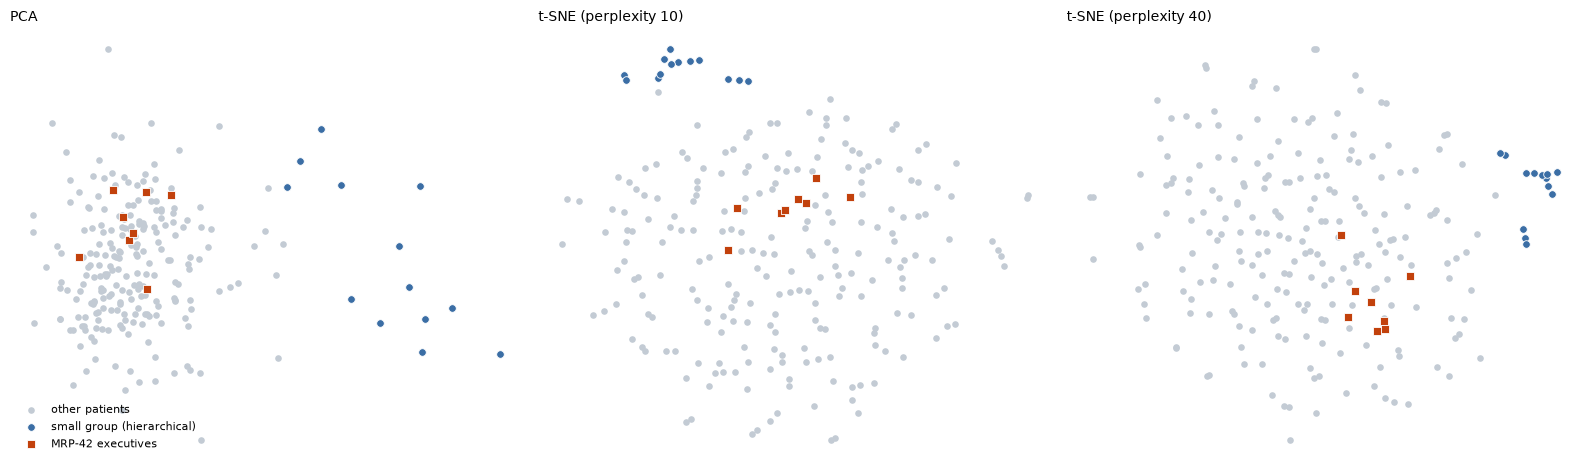

In [13]:
pc = PCA(2).fit_transform(Z)
maps = {"PCA": pc} | {f"t-SNE (perplexity {p})": TSNE(perplexity=p, random_state=0).fit_transform(Z) for p in [10, 40]}
elite = feat["N_MRP42"] >= 3
atypical = groups.isin(groups[small].unique()) & ~elite

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (title, xy) in zip(axes, maps.items()):
    ax.scatter(*xy[~atypical & ~elite].T, s=14, color="#c3cbd4", label="other patients")
    ax.scatter(*xy[atypical].T, s=30, color="#3b6ea5", edgecolor="white", linewidth=.6, label="small group (hierarchical)")
    ax.scatter(*xy[elite].T, s=40, marker="s", color="#c2410c", edgecolor="white", linewidth=.6, label="MRP-42 executives")
    ax.set_title(title, fontsize=10, loc="left"); ax.set_xticks([]); ax.set_yticks([])
    for side in ax.spines.values():
        side.set_visible(False)
axes[0].legend(fontsize=8, frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

On the three maps, the small group (in blue) is apart from the main cloud. The executives (in orange), on the contrary, are mixed with the other patients. t-SNE separates better than PCA, as the course announces, and the result stays the same with two different perplexity settings.

### 2.5 A second clustering: ageing

The executives are only distinguished by their biological age, which is only one variable out of 27. We therefore redo a clustering on the ageing variables alone: age gap, ageing speed (slope) and largest drop of the age gap between two visits.

In [14]:
AGE_VARS = ["AGE_GAP", "BIOAGE_SLOPE", "MAX_AGE_DROP"]
Z_age = StandardScaler().fit_transform(feat[AGE_VARS].fillna(feat[AGE_VARS].median()))
for k in range(2, 6):
    print(f"k={k} silhouette={silhouette_score(Z_age, KMeans(k, n_init=20, random_state=0).fit_predict(Z_age)):.2f}")

age_groups = pd.Series(KMeans(2, n_init=20, random_state=0).fit_predict(Z_age), index=feat.index)
rejuvenated = age_groups[age_groups == age_groups.value_counts().idxmin()].index
display(feat.loc[rejuvenated, AGE_VARS + ["N_MRP42"]].round(1).assign(occupation=occ[rejuvenated]).sort_values("N_MRP42", ascending=False))

k=2 silhouette=0.79
k=3 silhouette=0.54
k=4 silhouette=0.53
k=5 silhouette=0.53


,AGE_GAP,BIOAGE_SLOPE,MAX_AGE_DROP,N_MRP42,occupation
patient_number,,,,,
PAT-31221,-10.6,0.2,-6.5,5.0,Head of government of Kintara Republic
PAT-31174,-11.4,-0.2,-3.7,4.0,Regional governor in the Tembara Commonwealth
PAT-31044,-12.5,0.3,-4.4,4.0,Senior minister of the Avelora Federation
PAT-31119,-14.1,-0.9,-6.2,4.0,Chief executive of Solvane Energy Group
PAT-31074,-12.4,-0.9,-5.0,4.0,Executive chair of Nivren Maritime Logistics
PAT-31099,-8.9,-1.0,-5.3,3.0,Retired political intermediary and former coun...
PAT-31142,-10.9,-0.9,-5.7,3.0,Chair of Belen Agro-Industries
PAT-31183,-12.0,-0.9,-5.1,3.0,Executive director of Ardena Capital Union
PAT-31011,-7.0,-0.5,-10.9,1.0,transport worker


With 2 groups, the separation is very clear (silhouette 0.79). The small group has 17 rejuvenated patients:
* the 8 executives treated with `MRP-42`;
* 9 patients with no recorded repeated treatment (research coordinator, senior civil servant, regional manager, teacher, shopkeeper…), who nevertheless have a similar profile: age gap of −7 to −12 years and, for most, a sudden drop of 5 to 11 years from one visit to the next.

This is inconsistent: these 9 patients seem to have received the same treatment, but it does not appear in their procedures. These could be undeclared treatments. We will check in the following courses (anomalies, timeline) and by crossing with the other datasets.

### 2.6 Summary

Two small groups come out without our having designated them: 10 patients with an atypical physical profile, and 17 rejuvenated patients of whom only 8 have recorded injections. The two groups do not overlap.

## Course 3: Spotting patterns and detecting anomalies

We keep the three groups found in course 2 to interpret the results:
* ELITE: the 8 executives repeatedly treated with `MRP-42`;
* PHENO: the 10 patients with an atypical physical profile (small hierarchical group and outside any group for DBSCAN);
* UNDECLARED_REJUVENATED: the 9 rejuvenated patients with no recorded repeated treatment.

In [15]:
from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

elite_ids = feat.index[feat["N_MRP42"] >= 3]
pheno_ids = outside_group[small][lambda s: s].index
grp = pd.Series("other", index=feat.index)
grp[pheno_ids] = "PHENO"
grp[rejuvenated.difference(elite_ids)] = "UNDECLARED_REJUVENATED"
grp[elite_ids] = "ELITE"
grp.value_counts()

other                     213
PHENO                      10
UNDECLARED_REJUVENATED      9
ELITE                       8
Name: count, dtype: int64

### 3.1 Patterns: frequent itemsets and association rules

Each patient becomes a "transaction" that contains true or false items:
* anomalies, obtained by discretising the measurements as the course suggests (for example `idcons_low` = the 10% lowest values);
* their occupation, their clinic, the doctors who saw them, the procedures and the encounter types.

The Apriori algorithm looks for frequent combinations, then we derive "if X then Y" rules. A rule is interesting if its confidence is high (Y is almost always present when X is) and if its lift is well above 1 (X makes Y much more likely than by chance).

In [16]:
T = pd.DataFrame(index=feat.index)
for o in ["research professional", "corporate adviser", "clinical specialist"]:
    T["occupation=" + o] = occ.reindex(feat.index).eq(o)
T["detailed_occupation"] = P.set_index("patient_number")["occupation_detailed"].reindex(feat.index)
for fac in E["facility_license_number"].unique():
    T["seen_at_" + fac] = E[E["facility_license_number"] == fac].groupby("patient_number").size().reindex(feat.index).fillna(0) > 0
for lic in E["attending_license_number"].unique():
    T["doctor_" + lic[-8:]] = E[E["attending_license_number"] == lic].groupby("patient_number").size().reindex(feat.index).fillna(0) > 0
T["executive_review"] = feat["VISIT_executive_health_review"] > 0
T["MRP42_repeated"] = feat["N_MRP42"] >= 3
T["MRP42_one_dose"] = feat["N_MRP42"] == 1
T["young_bio_age"] = feat["AGE_GAP"] < -6
T["sudden_age_drop"] = feat["MAX_AGE_DROP"] < -4
T["discordant_pulse"] = feat["N_DISCORDANT"] >= 2
T["atypical_ocular"] = feat["N_OCULAR_ATYP"] >= 1
T["atypical_binocoord"] = feat["BINOCOORD_ATYP"] > 0
T["abnormal_vestib"] = feat["VESTIB_ABNORMAL"] > 0
for c, sens in [("LATSWAY", "high"), ("THORPEAK", "high"), ("IDCONS", "low"), ("CAMMATCH", "low"), ("THERMQUAL", "low")]:
    q = feat[c].quantile(.9 if sens == "high" else .1)
    T[f"{c.lower()}_{sens}"] = feat[c] > q if sens == "high" else feat[c] < q
T = T.fillna(False).astype(bool)

frequent = apriori(T, min_support=0.02, use_colnames=True, max_len=4)
rules = association_rules(frequent, metric="lift", min_threshold=2)
rules = rules[(rules["confidence"] >= .8) & (rules["consequents"].apply(len) == 1)]
rules["premise"] = rules["antecedents"].apply(lambda s: " + ".join(sorted(s)))
rules["conclusion"] = rules["consequents"].apply(lambda s: next(iter(s)))
print(f"{T.shape[1]} items, {len(frequent)} frequent itemsets, {len(rules)} rules (confidence ≥ 0.8, lift ≥ 2)")

def best_rules(conclusion, n=4):
    r = rules[(rules["conclusion"] == conclusion) & (rules["antecedents"].apply(len) <= 2)]
    return r.sort_values(["confidence", "support", "lift"], ascending=False).head(n)

columns = ["premise", "conclusion", "support", "confidence", "lift", "leverage"]
display(pd.concat([best_rules(a) for a in ["discordant_pulse", "young_bio_age", "MRP42_repeated", "sudden_age_drop"]])[columns].round(3))

29 items, 1361 frequent itemsets, 603 rules (confidence ≥ 0.8, lift ≥ 2)


,premise,conclusion,support,confidence,lift,leverage
1026,idcons_low + thorpeak_high,discordant_pulse,0.033,1.000,9.600,0.030
972,atypical_binocoord + latsway_high,discordant_pulse,0.029,1.000,9.600,0.026
978,atypical_binocoord + thorpeak_high,discordant_pulse,0.029,1.000,9.600,0.026
984,atypical_binocoord + idcons_low,discordant_pulse,0.029,1.000,9.600,0.026
21,executive_review,young_bio_age,0.083,1.000,5.714,0.069
671,doctor_MED-1002 + executive_review,young_bio_age,0.071,1.000,5.714,0.058
28,sudden_age_drop,young_bio_age,0.058,1.000,5.714,0.048
925,executive_review + sudden_age_drop,young_bio_age,0.058,1.000,5.714,0.048
845,doctor_RES-1044 + executive_review,sudden_age_drop,0.033,0.889,15.238,0.031
27,MRP42_repeated,sudden_age_drop,0.029,0.875,15.000,0.027


The strongest rules describe two "recipes":
* atypical profile: when two anomalies are present together (low identity and thoracic peak, or atypical eye coordination and sway…), the pulse is always discordant. Confidence 100%, lift 9.6: nearly 10 times more than chance;
* rejuvenation: all patients who have "executive health reviews" have a young biological age (confidence 100%, lift 5.7). Repeated `MRP-42` treatment causes a sudden drop in 7 cases out of 8 (lift 15).

### 3.2 Co-occurrences: who administers `MRP-42`?

The course recommends expressing a co-occurrence matrix in row percentages.

In [17]:
mrp_procedures = PR[PR["procedure_code"] == "MRP-42"].assign(group=lambda d: d["patient_number"].map(grp))
display((pd.crosstab(mrp_procedures["performing_license_number"], mrp_procedures["group"], normalize="index") * 100).round(0)
        .assign(n_procedures=mrp_procedures["performing_license_number"].value_counts()))
E["group"] = E["patient_number"].map(grp)
display((pd.crosstab(E["group"], E["encounter_type"], normalize="index") * 100).round(0)
        [["executive_health_review", "specialist_procedure", "cardiac_assessment", "ocular_assessment", "mobility_assessment"]])

group,ELITE,UNDECLARED_REJUVENATED,other,n_procedures
performing_license_number,,,,
LIC-VLN-MED-1001,0.0,0.0,100.0,1
LIC-VLN-MED-1002,83.0,3.0,14.0,36
LIC-VLN-MED-1003,0.0,0.0,100.0,1
LIC-VLN-MED-1004,0.0,0.0,100.0,3
LIC-VLN-MED-1006,0.0,0.0,100.0,4
LIC-VLN-RES-1016,0.0,0.0,100.0,3
LIC-VLN-RES-1044,0.0,0.0,100.0,2


encounter_type,executive_health_review,specialist_procedure,cardiac_assessment,ocular_assessment,mobility_assessment
group,,,,,
ELITE,56.0,44.0,0.0,0.0,0.0
PHENO,0.0,0.0,29.0,22.0,36.0
UNDECLARED_REJUVENATED,98.0,0.0,0.0,0.0,0.0
other,2.0,0.0,7.0,4.0,7.0


* Doctor `LIC-VLN-MED-1002` performed all 30 doses given to the executives. The 6 other `MRP-42` procedures he performed are single "research" doses.
* The undeclared rejuvenated patients only have "executive health reviews" (98% of their encounters), exactly like the executives. But they have no recorded "procedure" encounter, whereas it is during these encounters that the executives receive their doses.
* The PHENO group only has cardiac, ocular and mobility assessments: it is closely followed for its anomalies.

### 3.3 Univariate anomalies: IQR, z-score, modified z-score

We compare the three methods of the course on the 27 medical measurements per patient.

In [18]:
Xm = feat[MEDICAL]
q1, q3 = Xm.quantile(.25), Xm.quantile(.75)
methods = {
    "IQR": (Xm < q1 - 1.5 * (q3 - q1)) | (Xm > q3 + 1.5 * (q3 - q1)),
    "z-score > 3": ((Xm - Xm.mean()) / Xm.std()).abs() > 3,
    "modified z > 3.5": (0.6745 * (Xm - Xm.median()) / (Xm - Xm.median()).abs().median()).abs() > 3.5,
}
display(pd.DataFrame({m: {"outliers": a.sum().sum(), **a.sum(axis=1).groupby(grp).mean().round(2).to_dict()}
                      for m, a in methods.items()}))

,IQR,z-score > 3,modified z > 3.5
outliers,140.00,46.00,46.00
ELITE,0.12,0.00,0.00
PHENO,4.00,1.60,1.90
UNDECLARED_REJUVENATED,0.11,0.00,0.00
other,0.46,0.14,0.13


The IQR flags 3 times more values than the z-scores, because it is more sensitive to stretched distributions. Whatever the method, the PHENO group concentrates the outliers (2 to 4 per patient, versus 0.1 to 0.5 for the others). The executives and the rejuvenated patients have almost none: their particularity is not an extreme value, but a change over time.

### 3.4 Anomalies relative to the patient's history

This is the course's bank withdrawal example: a value can be normal for the population but abnormal for this person. We therefore compare each visit with the same patient's history, with a modified z-score (the patient's median and median absolute deviation).

In [19]:
rows = []
for pid, d in W2.groupby("patient_number"):
    s = d.set_index("encounter_number")["AGE_GAP"].dropna()
    if len(s) < 4:
        continue
    abs_dev = max((s - s.median()).abs().median(), 0.5)
    mod_z = 0.6745 * (s - s.median()) / abs_dev
    for enc, z in mod_z[mod_z.abs() > 6].items():
        rows.append((pid, enc, s[enc], s.median(), z))
breaks = pd.DataFrame(rows, columns=["patient", "encounter", "age gap", "patient median", "modified z"])
breaks = breaks.assign(date=breaks["encounter"].map(E.set_index("encounter_number")["encounter_start"]),
                           type=breaks["encounter"].map(E.set_index("encounter_number")["encounter_type"]),
                           group=breaks["patient"].map(grp))
breaks.sort_values("modified z").round({"age gap": 1, "patient median": 1, "modified z": 1})

,patient,encounter,age gap,patient median,modified z,date,type,group
0,PAT-31011,ENC-000780,-17.8,-7.0,-14.7,2021-05-01 13:15:00,executive_health_review,UNDECLARED_REJUVENATED
5,PAT-31122,ENC-000448,-19.1,-8.8,-13.8,2024-08-03 13:15:00,executive_health_review,UNDECLARED_REJUVENATED
2,PAT-31046,ENC-000347,-18.0,-8.5,-12.8,2025-06-20 13:15:00,executive_health_review,UNDECLARED_REJUVENATED
4,PAT-31110,ENC-000694,-15.9,-6.7,-12.3,2020-05-22 13:15:00,executive_health_review,UNDECLARED_REJUVENATED
1,PAT-31017,ENC-000162,-13.9,-7.3,-8.9,2025-06-20 13:15:00,executive_health_review,UNDECLARED_REJUVENATED
6,PAT-31179,ENC-000264,-13.5,-8.7,-6.4,2022-12-16 13:15:00,executive_health_review,UNDECLARED_REJUVENATED
3,PAT-31071,ENC-000232,-13.6,-9.2,-6.0,2024-02-23 13:15:00,executive_health_review,UNDECLARED_REJUVENATED


The clearest breaks (modified z from −6 to −15) concern the undeclared rejuvenated patients. They all occur during an "executive health review", and two of them fall on the same day, 20 June 2025.

### 3.5 Multivariate anomalies: Isolation Forest, LOF, ABOD

We apply the three methods of the course to the 27 standardised measurements, and rank the patients according to their mean rank.

In [20]:
iso_score = -IsolationForest(n_estimators=500, random_state=0).fit(Z).score_samples(Z)
score_lof = -LocalOutlierFactor(n_neighbors=20).fit(Z).negative_outlier_factor_

def abod(Z):
    # variance of the (distance-weighted) angles between a point and all pairs of other points
    result = np.empty(len(Z))
    for i in range(len(Z)):
        V = np.delete(Z, i, axis=0) - Z[i]
        n2 = (V ** 2).sum(axis=1)
        M = (V @ V.T) / np.outer(n2, n2)
        result[i] = M[np.triu_indices(len(V), 1)].var()
    return result

score_abod = -np.log(abod(Z))   # low angle variance = isolated point (log for a readable score)
scores = pd.DataFrame({"Isolation Forest": iso_score, "LOF": score_lof, "ABOD": score_abod}, index=feat.index)
scores["rank moyen"] = scores.rank(ascending=False).mean(axis=1)
top = scores.sort_values("rank moyen").head(15)
display(top.round(3).assign(group=grp[top.index], occupation=occ[top.index],
                            IDCONS=feat.loc[top.index, "IDCONS"], CAMMATCH=feat.loc[top.index, "CAMMATCH"]))
print({m: grp[scores[m].nlargest(15).index].value_counts().to_dict() for m in ["Isolation Forest", "LOF", "ABOD"]})

,Isolation Forest,LOF,ABOD,rank moyen,group,occupation,IDCONS,CAMMATCH
patient_number,,,,,,,,
PAT-31233,0.524,1.459,14.544,2.333,PHENO,research professional,36.3,59.5
PAT-31186,0.534,1.318,12.972,4.333,PHENO,corporate adviser,96.7,81.9
PAT-31086,0.531,1.246,13.299,4.667,PHENO,corporate adviser,76.2,59.2
PAT-31065,0.534,1.241,13.130,5.667,PHENO,clinical specialist,91.3,74.1
PAT-31139,0.502,1.383,13.074,5.667,other,retired professional,73.2,40.6
PAT-31037,0.517,1.258,13.269,6.000,PHENO,research professional,66.7,68.0
PAT-31181,0.519,1.343,12.770,6.333,other,transport worker,97.1,100.0
PAT-31152,0.525,1.334,12.719,6.333,other,small-business owner,100.0,78.1
PAT-31162,0.518,1.244,12.893,8.000,PHENO,corporate adviser,68.6,73.7


{'Isolation Forest': {'PHENO': 8, 'other': 7}, 'LOF': {'PHENO': 8, 'other': 7}, 'ABOD': {'PHENO': 9, 'other': 6}}


The three methods place 8 or 9 PHENO patients in their top 15. They also bring out a few ordinary patients that the previous steps had not isolated:
* some have a very low camera recognition or identity consistency without any other anomaly. For example `PAT-31139` (camera 40.6, the lowest of all) and `PAT-31031` (identity 63.8). Is the person measured really the right one?
* others have a single strong anomaly (abnormal vestibular test, isolated discordant pulse). These are probably the control cases mentioned in the clinical notes.

### 3.6 An abnormal event: 20 June 2025

In [21]:
E["day"] = E["encounter_start"].dt.date.astype(str)
print("Days with the most encounters:", E["day"].value_counts().head(3).to_dict())

overlaps = []
for doctor, d in E.sort_values("encounter_start").groupby("attending_license_number"):
    d = d.reset_index(drop=True)
    for i in range(len(d)):
        for j in range(i + 1, len(d)):
            if d.loc[j, "encounter_start"] >= d.loc[i, "encounter_end"]:
                break
            overlaps.append((doctor, d.loc[i, "day"], d.loc[i, "facility_license_number"] != d.loc[j, "facility_license_number"]))
overlap_df = pd.DataFrame(overlaps, columns=["doctor", "day", "two clinics at once"])
display(overlap_df.groupby("day").agg(simultaneous_visits=("doctor", "size"), in_two_clinics=("two clinics at once", "sum"))
        .sort_values("simultaneous_visits", ascending=False).head(3))

june20 = E[E["day"] == "2025-06-20"]
print("Encounters on 20/06/2025:", len(june20), "| of which at 13:15:", (june20["encounter_start"].dt.strftime("%H:%M") == "13:15").sum(),
      "| scheduled in advance as follow-up:", pd.to_datetime(E["follow_up_date"]).dt.date.astype(str).eq("2025-06-20").sum())
display(june20.groupby("attending_license_number")["facility_license_number"].agg(lambda s: dict(s.value_counts())).rename("clinics"))

Days with the most encounters: {'2025-06-20': 22, '2019-09-04': 3, '2021-07-18': 3}


,simultaneous_visits,in_two_clinics
day,,
2025-06-20,25,11
2023-06-17,3,2
2018-07-21,1,1


Encounters on 20/06/2025: 22 | of which at 13:15: 17 | scheduled in advance as follow-up: 22


attending_license_number
LIC-VLN-MED-1001                 {'FAC-AVL-301': 1, 'FAC-VLN-101': 1}
LIC-VLN-MED-1002                 {'FAC-VLN-101': 5, 'FAC-AVL-201': 1}
LIC-VLN-MED-1004    {'FAC-AVL-301': 1, 'FAC-AVL-201': 1, 'FAC-VLN-...
LIC-VLN-MED-1005                                   {'FAC-VLN-101': 2}
LIC-VLN-MED-1006                                   {'FAC-VLN-101': 2}
LIC-VLN-RES-1016                 {'FAC-VLN-101': 3, 'FAC-AVL-301': 1}
LIC-VLN-RES-1044                 {'FAC-AVL-201': 2, 'FAC-VLN-101': 1}
Name: clinics, dtype: object

20 June 2025 looks like no other day:
* 22 encounters, whereas no other day has more than 3. They were all set months in advance as a follow-up date;
* they all take place at the same time. The time itself means nothing: in this data, it only depends on the rank of the visit (1st visit at 9:15, 2nd at 10:15…), which is a generation artefact. What is abnormal is that all these visits fall on the same day;
* the doctors are in several encounters at the same time, sometimes in two clinics of two different countries (Valenne and Avelora). A doctor cannot be in two countries at the same time.

These encounters cannot be real: either they were entered in bulk or invented, or they hide a particular event. Two undeclared rejuvenated patients undergo their biological age drop there. This date must be looked for in the other datasets when we pool our results.

### 3.7 Summary

The association rules and the anomalies restate the two profiles. What is new: the undeclared rejuvenated patients have the same path as the executives without the procedure, and 20 June 2025 cannot correspond to real encounters.

## Course 4: Mining graphs and processes

### 4.1 The patient – doctor network

We build a bipartite graph: the nodes are the patients and the doctors, and a link connects a patient to a doctor who saw them, weighted by the number of encounters. We first describe it with the measures of the course.

In [22]:
import networkx as nx
from networkx.algorithms import community as nxc

B = nx.Graph()
for (p_, m_), w in E.groupby(["patient_number", "attending_license_number"]).size().items():
    B.add_edge(p_, m_, weight=w)
doctors = sorted(E["attending_license_number"].unique())
print(f"N = {B.number_of_nodes()} nodes ({len(doctors)} doctors), L = {B.number_of_edges()} links, "
      f"bipartite density = {B.number_of_edges() / (len(doctors) * (B.number_of_nodes() - len(doctors))):.2f}")

E["restricted"] = E["confidentiality_class"] == "restricted"
display(pd.DataFrame({
    "degree (patients)": {m_: B.degree(m_) for m_ in doctors},
    "strength (encounters)": {m_: B.degree(m_, weight="weight") for m_ in doctors},
    "% restricted encounters": E.groupby("attending_license_number")["restricted"].mean().mul(100).round(0),
    "executive encounters": E[E["group"] == "ELITE"].groupby("attending_license_number").size(),
}).fillna(0))

N = 248 nodes (8 doctors), L = 844 links, bipartite density = 0.44


,degree (patients),strength (encounters),% restricted encounters,executive encounters
LIC-VLN-MED-1001,118,147,22.0,12
LIC-VLN-MED-1002,112,162,39.0,33
LIC-VLN-MED-1003,99,121,9.0,5
LIC-VLN-MED-1004,98,121,11.0,6
LIC-VLN-MED-1005,96,119,16.0,4
LIC-VLN-MED-1006,110,136,14.0,3
LIC-VLN-RES-1016,112,140,14.0,1
LIC-VLN-RES-1044,99,121,11.0,4


The 8 doctors all have a similar degree (96 to 118 patients each): from afar, each doctor sees a bit of everyone. The only clear difference: `MED-1002` has 33 executive encounters, versus 1 to 12 for the others, and 39% of his encounters are restricted.

To go further, we connect two patients when they are followed by the same doctors in the same proportions (similarity of their doctor profiles, keeping only the closest 5% of pairs). We then look for communities with the Louvain algorithm. We rerun it with several thresholds and several initialisations to check that the result is stable.

In [23]:
doctor_profile = E.groupby(["patient_number", "attending_license_number"]).size().unstack(fill_value=0)
doctor_profile = doctor_profile.div(doctor_profile.sum(axis=1), axis=0)
similarity = (doctor_profile @ doctor_profile.T).to_numpy(copy=True)
np.fill_diagonal(similarity, 0)

def patient_graph(q):
    threshold = np.quantile(similarity[np.triu_indices(len(similarity), 1)], q)
    G = nx.Graph()
    G.add_nodes_from(doctor_profile.index)
    ii, jj = np.where(np.triu(similarity > threshold, 1))
    G.add_weighted_edges_from((doctor_profile.index[i], doctor_profile.index[j], similarity[i, j]) for i, j in zip(ii, jj))
    return G

G = patient_graph(.95)
print(f"Patient graph: N = {G.number_of_nodes()}, L = {G.number_of_edges()}, density = {nx.density(G):.3f}, "
      f"mean clustering coefficient = {nx.average_clustering(G):.2f}")

stability = []
for q in [.9, .95, .98]:
    Gq = patient_graph(q)
    for seed in [0, 1, 2]:
        comms = nxc.louvain_communities(Gq, weight="weight", seed=seed)
        c_elite = [c for c in comms if set(elite_ids) & c]
        stability.append({"threshold": q, "seed": seed, "communities": len(comms),
                          "modularity": round(nxc.modularity(Gq, comms, weight="weight"), 2),
                          "communities containing executives": len(c_elite),
                          "size": len(c_elite[0]), "executives inside": len(set(elite_ids) & c_elite[0]),
                          "dominant doctor": doctor_profile.loc[list(c_elite[0])].mean().idxmax(),
                          "communities of the 9 undeclared rejuvenated": len([c for c in comms if set(grp[grp == "UNDECLARED_REJUVENATED"].index) & c])})
display(pd.DataFrame(stability))

Patient graph: N = 240, L = 1304, density = 0.045, mean clustering coefficient = 0.42


,threshold,seed,communities,modularity,communities containing executives,size,executives inside,dominant doctor,communities of the 9 undeclared rejuvenated
0,0.90,0,28,0.46,1,48,8,LIC-VLN-MED-1002,7
1,0.90,1,29,0.46,1,45,8,LIC-VLN-MED-1002,8
2,0.90,2,28,0.45,1,51,8,LIC-VLN-MED-1002,7
3,0.95,0,72,0.55,1,32,8,LIC-VLN-MED-1002,8
4,0.95,1,71,0.56,1,34,8,LIC-VLN-MED-1002,8
5,0.95,2,71,0.55,1,34,8,LIC-VLN-MED-1002,8
6,0.98,0,88,0.65,1,30,8,LIC-VLN-MED-1002,8
7,0.98,1,88,0.65,1,30,8,LIC-VLN-MED-1002,8
8,0.98,2,88,0.65,1,33,8,LIC-VLN-MED-1002,8


In the 9 trials, the 8 executives are always in the same community, always organised around doctor `MED-1002`. The modularity (0.45 to 0.65) indicates a real community structure. The undeclared rejuvenated patients, on the other hand, are scattered among the communities: they do not go through a single doctor, which makes their treatment harder to spot.

### 4.2 The important nodes

We add to the graph the clinics, the encounter types and the procedure types, then measure the importance of each patient: its degree, its betweenness (how much it serves as a "bridge" between parts of the network) and its closeness (how close it is to all the other nodes).

In [24]:
G4 = nx.Graph()
for r in E.itertuples():
    G4.add_edges_from([(r.patient_number, r.attending_license_number), (r.patient_number, r.facility_license_number),
                       (r.patient_number, "TYPE:" + r.encounter_type)])
for r in PR.itertuples():
    G4.add_edges_from([(r.patient_number, "PROC:" + r.procedure_code), (r.performing_license_number, "PROC:" + r.procedure_code)])
centrality = pd.DataFrame({"degree": dict(G4.degree()), "betweenness": nx.betweenness_centrality(G4),
                      "closeness": nx.closeness_centrality(G4)})
centrality = centrality[centrality.index.str.startswith("PAT")]
display(centrality.groupby(grp).mean().round(4))

,degree,betweenness,closeness
ELITE,8.6250,0.0013,0.4925
PHENO,9.9000,0.0012,0.4992
UNDECLARED_REJUVENATED,7.6667,0.0005,0.4918
other,7.6573,0.0003,0.4927


The executives and the PHENO patients have a betweenness about 4 times higher than the other patients. They are connected to rare nodes that almost nobody else touches: "procedure" encounters, targeted ocular or cardiac assessments, clinic `FAC-AVL-301`. They are therefore "apart" patients in the organisation of care, not only in their measurements.

### 4.3 Process mining: the patients' path

We build an event log: for each patient, the chronological sequence of their encounters (by type), procedures and cardiac recordings. Each patient forms a "trace". From it we derive the graph of direct successions ("A then B"), group by group.

In [25]:
events = pd.concat([
    E[["patient_number", "encounter_start", "encounter_type"]].set_axis(["patient", "t", "step"], axis=1),
    PR.assign(t=pd.to_datetime(PR["performed_time"]), step="procedure " + PR["procedure_code"])[["patient_number", "t", "step"]].set_axis(["patient", "t", "step"], axis=1),
    CR.assign(t=pd.to_datetime(CR["recording_date"]), step="ECG " + CR["recording_context"])[["patient_number", "t", "step"]].set_axis(["patient", "t", "step"], axis=1),
]).sort_values(["patient", "t"])
traces = events.groupby("patient")["step"].apply(lambda s: ("START",) + tuple(s) + ("END",))
print(f"{len(events)} events, {traces.nunique()} different paths for {len(traces)} patients")

def transitions(trace_list):
    c = Counter()
    for t in trace_list:
        c.update(zip(t, t[1:]))
    return c

from collections import Counter
dfg = {g_: transitions(traces[grp.reindex(traces.index) == g_]) for g_ in ["ELITE", "UNDECLARED_REJUVENATED", "PHENO"]}
display(pd.DataFrame({g_: [f"{a} → {b} ({n})" for (a, b), n in c.most_common(5)] for g_, c in dfg.items()}))

1421 events, 229 different paths for 240 patients


,ELITE,UNDECLARED_REJUVENATED,PHENO
0,specialist_procedure → procedure MRP-42 (30),executive_health_review → executive_health_rev...,START → cardiac_assessment (5)
1,executive_health_review → specialist_procedure...,START → executive_health_review (9),cardiac_assessment → cardiac_assessment (4)
2,procedure MRP-42 → executive_health_review (26),executive_health_review → procedure AGE-PNL (4),mobility_assessment → mobility_assessment (4)
3,START → executive_health_review (8),executive_health_review → END (4),cardiac_assessment → mobility_assessment (3)
4,executive_health_review → END (8),procedure AGE-PNL → executive_health_review (3),specialist_follow_up → mobility_assessment (3)


We also apply the Heuristic Miner to the whole log. For each succession A → B, it computes a dependency degree between −1 and 1: close to 1, it means that "A is almost always followed by B, and never the reverse".

In [26]:
all_transitions = transitions(traces)
dependency = pd.Series({(a, b): (n - all_transitions[(b, a)]) / (n + all_transitions[(b, a)] + 1) for (a, b), n in all_transitions.items() if a != b})
dependency = dependency[~dependency.index.map(lambda x: x[0] == "START" or x[1] == "END")]
display(dependency.sort_values(ascending=False).head(6).round(2).rename("dependency").to_frame())

ev_elite = events[events["patient"].isin(elite_ids)].copy()
ev_elite["next delay (days)"] = ev_elite.groupby("patient")["t"].shift(-1).sub(ev_elite["t"]).dt.days
print("Delay between an MRP-42 injection and the next step:",
      ev_elite.loc[ev_elite["step"] == "procedure MRP-42", "next delay (days)"].describe()[["mean", "std", "min", "max"]].round(0).to_dict())

,,dependency
specialist_procedure,procedure MRP-42,0.97
procedure MRP-42,executive_health_review,0.96
executive_health_review,specialist_procedure,0.96
research_procedure,procedure MRP-42,0.95
general_examination,research_procedure,0.83
specialist_follow_up,research_procedure,0.83


Delay between an MRP-42 injection and the next step: {'mean': 35.0, 'std': 6.0, 'min': 27.0, 'max': 43.0}


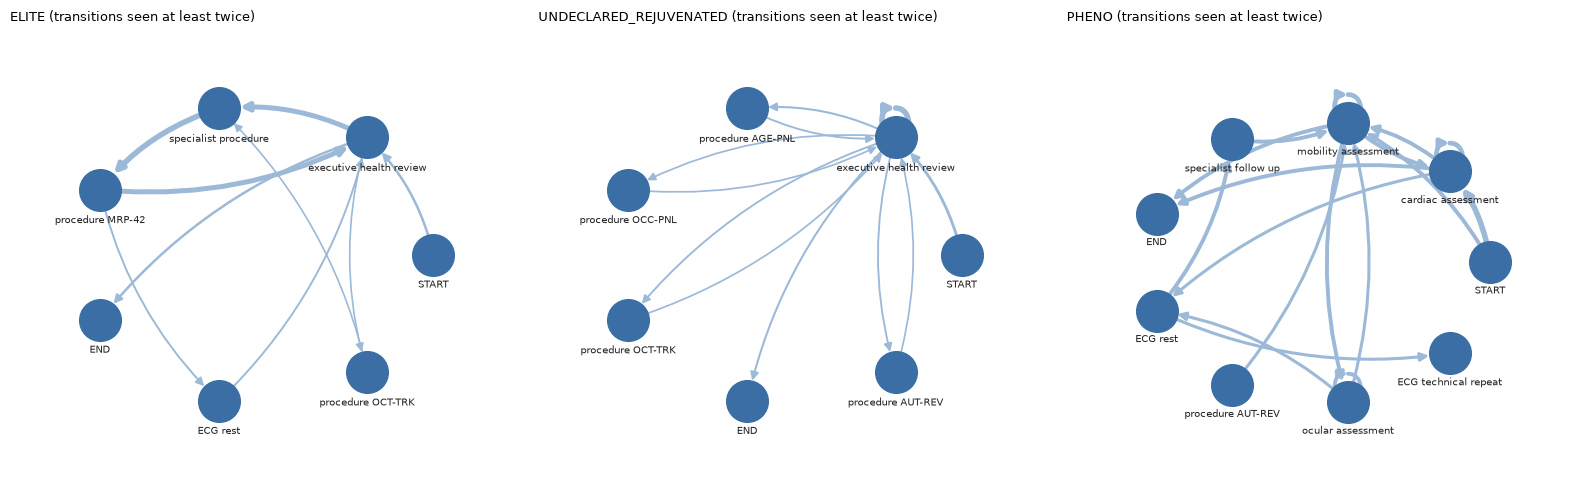

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (g_, c) in zip(axes, dfg.items()):
    H = nx.DiGraph()
    for (a, b), n in c.items():
        if n >= 2:
            H.add_edge(a, b, weight=n)
    pos = nx.circular_layout(H)
    weights = [H[u][v]["weight"] for u, v in H.edges()]
    nx.draw_networkx_edges(H, pos, ax=ax, width=[1 + 3 * w / max(weights) for w in weights], edge_color="#9db9d8",
                           arrows=True, arrowsize=12, connectionstyle="arc3,rad=0.15", node_size=900)
    nx.draw_networkx_nodes(H, pos, ax=ax, node_size=900, node_color="#3b6ea5")
    for n_, (x, y) in pos.items():
        ax.text(x, y - 0.17, n_.replace("_", " "), ha="center", va="top", fontsize=7, color="#222")
    ax.set_title(f"{g_} (transitions seen at least twice)", fontsize=9, loc="left")
    ax.axis("off"); ax.margins(0.2)
plt.tight_layout(); plt.show()

The three groups have very different paths, and very different from that of ordinary patients (general examination, follow-up, occupational assessment):
* ELITE: a perfectly regular cycle. "Executive review", then "procedure" encounter, then `MRP-42` injection, then "executive review" about 35 days later (standard deviation of 6 days). The Heuristic Miner confirms this cycle with dependencies of 0.96 to 0.97;
* UNDECLARED_REJUVENATED: a simple loop "executive review" → "executive review", without a procedure step. It is the executives' cycle without the injection, while the effect (the rejuvenation) is the same;
* PHENO: a back-and-forth between cardiac, mobility and ocular assessments, with repeated ECGs. This is the path of specialised monitoring.

### 4.4 Product traceability: the lot numbers

Each `MRP-42` injection carries a material reference `MTL-year-number`. We sort the lots by number.

In [28]:
lots = PR[PR["procedure_code"] == "MRP-42"].copy()
lots["series"] = np.where(lots["material_reference"].str.startswith("MTL-R"), "research (MTL-R)", "executives (MTL)")
lots["number"] = lots["material_reference"].str[-4:].astype(int)
blocks = (lots[lots["series"] == "executives (MTL)"].groupby("patient_number")
         .agg(lots=("number", lambda s: f"{s.min()} to {s.max()}"), first_lot=("number", "min"), first_injection=("performed_time", "min"))
         .sort_values("first_lot").join(occ))
display(blocks)
print("Numbers used:", lots.groupby("series")["number"].agg(["min", "max", "count"]).to_dict("index"))

,lots,first_lot,first_injection,occupation_text
patient_number,,,,
PAT-31221,2 to 6,2,2016-02-18T09:05:00,Head of government of Kintara Republic
PAT-31044,7 to 10,7,2017-05-12T09:05:00,Senior minister of the Avelora Federation
PAT-31174,11 to 14,11,2015-09-10T09:05:00,Regional governor in the Tembara Commonwealth
PAT-31119,15 to 18,15,2018-01-26T09:05:00,Chief executive of Solvane Energy Group
PAT-31074,19 to 22,19,2017-11-03T09:05:00,Executive chair of Nivren Maritime Logistics
PAT-31183,23 to 25,23,2016-06-16T09:05:00,Executive director of Ardena Capital Union
PAT-31142,26 to 28,26,2019-03-14T09:05:00,Chair of Belen Agro-Industries
PAT-31099,29 to 31,29,2014-07-18T09:05:00,Retired political intermediary and former coun...


Numbers used: {'executives (MTL)': {'min': 2, 'max': 31, 'count': 30}, 'research (MTL-R)': {'min': 32, 'max': 51, 'count': 20}}


* Lot numbers 2 to 31 are assigned in consecutive blocks to each executive, and in the order of the hierarchy: head of government (lots 2 to 6), minister, governor, then the CEOs, and the former political intermediary last. This is not the chronological order: the former intermediary receives lot 29 as early as 2014, two years before lot 2 is used. One may think that the doses were reserved in advance for each executive, but this is only a hypothesis.
* The "research" series (`MTL-R`) follows (32 to 51) for 20 ordinary patients.
* Lot no. 1 appears nowhere. Was a dose administered without being recorded, or to someone who is not in this dataset? This is to be looked for in the orders and deliveries of the `logistics` dataset.

### 4.5 Summary

The executives form a community around `MED-1002` and follow a regular cycle. The undeclared rejuvenated patients have the same cycle, without the injection. The lots were assigned in the order of the hierarchy, and lot no. 1 is missing.

## Course 5: Mining spatial and temporal data

### 5.1 Spatial data

The health dataset contains no coordinates. We only have each patient's region (5 regions) and each clinic's country, coded in its identifier (`VLN` = Valenne, `AVL` = Avelora). With 5 regions without neighbourhood information and 3 clinics, Moran's I or LISA would make no sense. We therefore simply look at whether the groups are concentrated somewhere.

In [29]:
P_idx = P.set_index("patient_number")
display(pd.crosstab(P_idx["home_region"], grp.reindex(P_idx.index)))
display((pd.crosstab(E["group"], E["facility_license_number"], normalize="index") * 100).round(0))

col_0,ELITE,PHENO,UNDECLARED_REJUVENATED,other
home_region,,,,
Avelora Federation,2,2,4,46
Kintara Republic,2,1,1,43
Nordhaven Union,1,1,1,49
Tembara Commonwealth,1,1,1,36
Valenne Republic,2,5,2,39


facility_license_number,FAC-AVL-201,FAC-AVL-301,FAC-VLN-101
group,,,
ELITE,47.0,0.0,53.0
PHENO,29.0,31.0,40.0
UNDECLARED_REJUVENATED,33.0,11.0,57.0
other,26.0,10.0,64.0


* The three groups come from all regions. No geographic concentration appears, so a local cause (environment, exposure) is unlikely.
* The PHENO patients go much more often to the laboratory `FAC-AVL-301` ("Threshold Earth Avelora Laboratory", environmental health research): 31% of their encounters, versus 10% for the others. The executives never go there. They are seen only at the central clinic and the "executive" clinic of Avelora.

The coordinates of the clinics are in `public_records`. The spatial analysis will make sense when we pool our results, for example with the `ecology` sites located near the Avelora clinics.

### 5.2 Time series of the encounters

We count the encounters per month and decompose the series as in the course: a trend (12-month moving average), a seasonality (average of each month once the trend is removed) and a residual. We also compute the autocorrelation (ACF), and look for abnormal months with a rolling window (z-score relative to the median of the 13 months around).

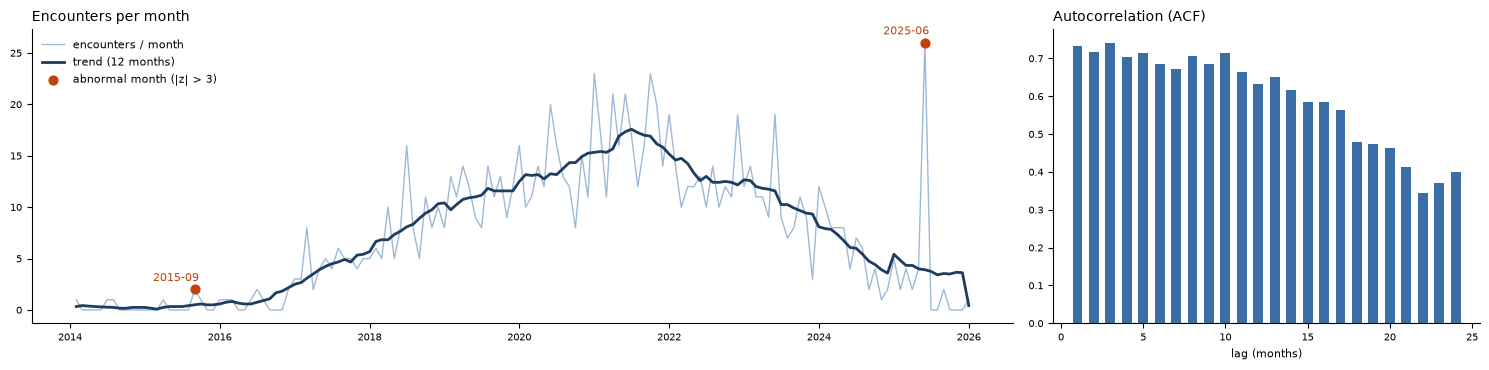

Seasonality amplitude (gap between months): 4.4 encounters


In [30]:
monthly = E.set_index("encounter_start").resample("MS").size()
trend = monthly.rolling(12, center=True, min_periods=6).mean()
season = (monthly - trend).groupby(monthly.index.month).mean()
residual = monthly - trend - monthly.index.month.map(season).values
window = monthly.rolling(13, center=True, min_periods=6)
rolling_z = (monthly - window.median()) / window.std()
x = (monthly - monthly.mean()).values
acf = [np.corrcoef(x[:-k], x[k:])[0, 1] for k in range(1, 25)]

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [2.3, 1]})
axes[0].plot(monthly.index, monthly, color="#9db9d8", linewidth=1, label="encounters / month")
axes[0].plot(trend.index, trend, color="#1d3c5e", linewidth=2, label="trend (12 months)")
anom = rolling_z[rolling_z.abs() > 3]
axes[0].scatter(anom.index, monthly[anom.index], color="#c2410c", zorder=3, s=40, label="abnormal month (|z| > 3)")
for d_, v in monthly[anom.index].items():
    axes[0].annotate(d_.strftime("%Y-%m"), (d_, v), textcoords="offset points", xytext=(-30, 6), fontsize=8, color="#c2410c")
axes[0].legend(fontsize=8, frameon=False); axes[0].set_title("Encounters per month", fontsize=10, loc="left")
axes[1].bar(range(1, 25), acf, color="#3b6ea5", width=.6)
axes[1].set_xlabel("lag (months)", fontsize=8); axes[1].set_title("Autocorrelation (ACF)", fontsize=10, loc="left")
for ax in axes:
    ax.tick_params(labelsize=7)
    for s_ in ["top", "right"]:
        ax.spines[s_].set_visible(False)
plt.tight_layout(); plt.show()
print("Seasonality amplitude (gap between months):", round(season.max() - season.min(), 1), "encounters")

* The series is dominated by a trend: rise from 2017 to 2021, then decline. It matches the arrival of the patients, all registered between 2017 and 2021, with a few exceptions.
* The ACF decreases slowly, without a peak at 12 months: there is no seasonality.
* The rolling window flags June 2025: this is the 20 June seen in course 3, which stands out even on the monthly series. September 2015 is also flagged, but it rests on only 3 encounters.

### 5.3 Timeline of the groups

In [31]:
start = E.groupby("group")["encounter_start"].agg(["min", "max"]).apply(lambda c: c.dt.date).rename(columns={"min": "first encounter", "max": "last encounter"})
mrp_by_year = PR[PR["procedure_code"] == "MRP-42"].assign(year=lambda d: pd.to_datetime(d["performed_time"]).dt.year)
display(start)
display(pd.crosstab(mrp_by_year["authorization_class"], mrp_by_year["year"]))

,first encounter,last encounter
group,,
ELITE,2014-02-18,2025-03-05
PHENO,2017-02-05,2026-01-11
UNDECLARED_REJUVENATED,2016-12-15,2025-06-20
other,2017-01-20,2025-06-20


year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
authorization_class,,,,,,,,,,,,
research_restricted,0,0,0,0,0,1,3,3,2,9,2,0
restricted_specialist,1,1,3,3,4,4,3,3,3,1,3,1


* The executives are treated from 2014, three years before the arrival of the general population (2017). The clinic seems to have first served this programme.
* The "research" doses (one per patient) only start in 2019, five years after the first doses given to the executives. It is therefore not a preliminary trial: the "research" comes afterwards, and could serve as a cover.

### 5.4 The effect of each dose over time

For each `MRP-42` injection, we compare the biological age gap at the visit just before and at the visit just after.

In [32]:
with_age = W2.dropna(subset=["AGE_GAP"])
effects = []
doses = PR[PR["procedure_code"] == "MRP-42"].assign(t=lambda d: pd.to_datetime(d["performed_time"])).sort_values("t")
doses["rank"] = doses.groupby("patient_number").cumcount() + 1
for r in doses.itertuples():
    v = with_age[with_age["patient_number"] == r.patient_number]
    before, after = v[v["encounter_start"] < r.t].tail(1), v[v["encounter_start"] > r.t].head(1)
    if len(before) and len(after):
        effects.append((r.patient_number, r.authorization_class, r.rank, after["AGE_GAP"].iloc[0] - before["AGE_GAP"].iloc[0]))
effects = pd.DataFrame(effects, columns=["patient", "class", "dose rank", "effect (years)"])
display(effects.groupby(["class", "dose rank"])["effect (years)"].agg(["mean", "min", "max", "count"]).round(1))

mean  min  max  count
class                 dose rank                       
research_restricted   1           0.0 -0.0  0.0      8
restricted_specialist 1          -3.5 -5.7 -0.3      5
                      2          -3.6 -6.2 -0.9      8
                      3          -3.8 -6.5  1.3      8
                      4          -0.3 -4.6  3.0      5
                      5           8.2  8.2  8.2      1

* In the executives, each of the first 3 doses rejuvenates by about 3.5 years, an effect measured about 35 days after the dose.
* From the 4th dose, the effect disappears or reverses. For example, the head of government "ages back" by 8 years after his 5th dose in 2024. The treatment could lose its efficacy, or cause a rebound.
* The 20 "research" doses have no effect (0.0 years). Placebo or fictitious dose: in any case, it is not the same product as the executives'.

### 5.5 Clustering of the age trajectories (DTW)

Each patient has a trajectory of age gap over their visits. The trajectories have neither the same length nor the same dates, so we compare them with Dynamic Time Warping (DTW), which realigns two series before comparing them. Each trajectory is brought back to 0 at the first visit, to compare evolutions and not levels. We then apply a hierarchical clustering on the DTW distances.

In [33]:
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

traj = {p_: d.sort_values("encounter_start")["AGE_GAP"].values for p_, d in with_age.groupby("patient_number")}
traj = {p_: s - s[0] for p_, s in traj.items() if len(s) >= 2}
ids = list(traj)

def dtw(a, b):
    D = np.full((len(a) + 1, len(b) + 1), np.inf)
    D[0, 0] = 0
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            D[i, j] = abs(a[i - 1] - b[j - 1]) + min(D[i - 1, j], D[i, j - 1], D[i - 1, j - 1])
    return D[-1, -1]

dist = np.zeros((len(ids), len(ids)))
for i in range(len(ids)):
    for j in range(i + 1, len(ids)):
        dist[i, j] = dist[j, i] = dtw(traj[ids[i]], traj[ids[j]])
dtw_groups = pd.Series(fcluster(linkage(squareform(dist), "average"), 2, "maxclust"), index=ids)
display(pd.crosstab(dtw_groups.rename("DTW group"), grp.reindex(ids)))

col_0,ELITE,PHENO,UNDECLARED_REJUVENATED,other
DTW group,,,,
1,0,10,5,212
2,8,0,4,0


DTW isolates a group of 12 trajectories: the 8 executives and 4 undeclared rejuvenated patients, with no ordinary patient. These 4 patients therefore have the same evolution as the treated executives, which strengthens the hypothesis of unrecorded injections. The other 5 rejuvenated patients have a flatter evolution, but a biological age already low from their first visit.

### 5.6 The cardiac signal: two independent rhythms

The clinical notes speak of a "second pulsatile source" in the thorax. We check this on the 44 ECG recordings (2 channels). On each channel, we detect the beats (signal peaks), deduce the heart rate, then measure the share of synchronous beats between the two channels (peaks less than 50 ms apart).

In [34]:
from scipy.signal import find_peaks

SIG = pd.read_csv(D / "cardiac_signal_samples.csv")
beats = []
for r in CR.itertuples():
    s = SIG[SIG["recording_id"] == r.recording_id].sort_values("time_ms")
    t = s["time_ms"].values / 1000
    pics = {c: t[find_peaks(s[c].values, height=.9, distance=int(.3 * r.sampling_rate_hz))[0]]
            for c in ["channel_a_normalized", "channel_b_normalized"]}
    a, b = pics.values()
    beats.append({"recording": r.recording_id, "patient": r.patient_number, "context": r.recording_context,
                       "bpm channel A": round(60 / np.median(np.diff(a))), "bpm channel B": round(60 / np.median(np.diff(b))),
                       "synchronous beats": round(np.mean([np.min(np.abs(b - x)) < .05 for x in a]), 2)})
beats = pd.DataFrame(beats)
beats["group"] = beats["patient"].map(grp)
display(beats.groupby("group")["synchronous beats"].agg(["mean", "min", "max", "count"]).round(2))
display(beats.sort_values("synchronous beats").head(12))

,mean,min,max,count
group,,,,
ELITE,1.00,0.98,1.00,4
PHENO,0.18,0.13,0.27,8
UNDECLARED_REJUVENATED,1.00,1.00,1.00,1
other,0.89,0.30,1.00,31


,recording,patient,context,bpm channel A,bpm channel B,synchronous beats,group
2,CRD-410025,PAT-31040,rest,80,99,0.13,PHENO
4,CRD-410014,PAT-31233,rest,74,90,0.14,PHENO
6,CRD-410005,PAT-31065,technical_repeat,67,100,0.15,PHENO
0,CRD-410031,PAT-31162,rest,70,88,0.15,PHENO
3,CRD-410016,PAT-31115,rest,86,81,0.17,PHENO
1,CRD-410019,PAT-31162,technical_repeat,71,88,0.17,PHENO
7,CRD-410022,PAT-31037,rest,71,97,0.24,PHENO
5,CRD-410038,PAT-31065,rest,66,99,0.27,PHENO
43,CRD-410028,PAT-31211,technical_repeat,72,54,0.30,other
41,CRD-410017,PAT-31130,technical_repeat,71,56,0.32,other


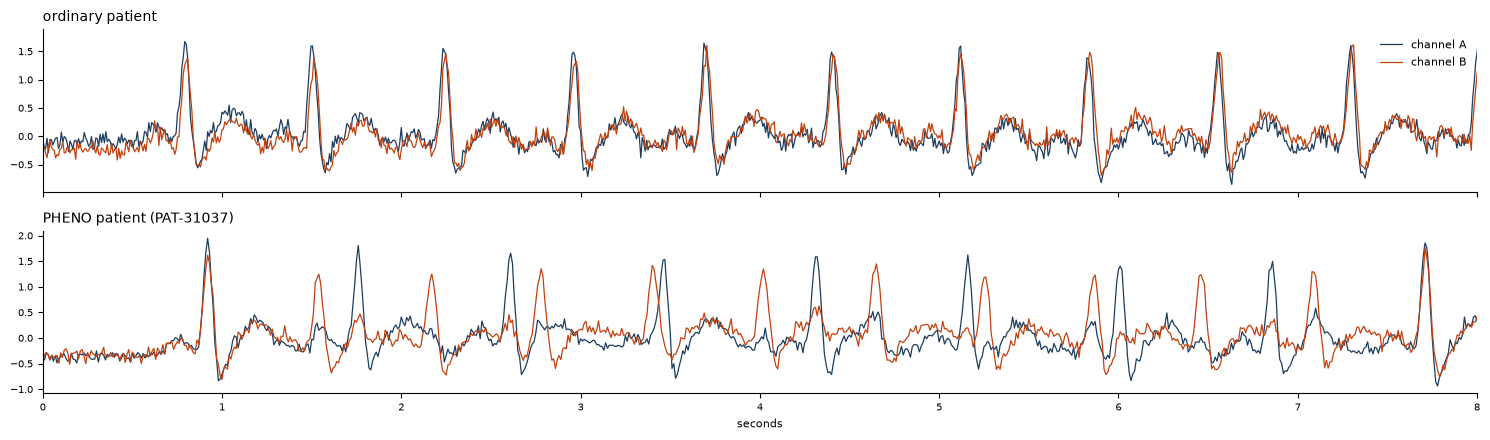

In [35]:
examples = [("CRD-410034", "ordinary patient"), ("CRD-410022", "PHENO patient (PAT-31037)")]
fig, axes = plt.subplots(2, 1, figsize=(15, 4.5), sharex=True)
for ax, (rec, title) in zip(axes, examples):
    s = SIG[SIG["recording_id"] == rec]
    ax.plot(s["time_ms"] / 1000, s["channel_a_normalized"], color="#1d3c5e", linewidth=.9, label="channel A")
    ax.plot(s["time_ms"] / 1000, s["channel_b_normalized"], color="#c2410c", linewidth=.9, label="channel B")
    ax.set_title(title, fontsize=10, loc="left"); ax.set_xlim(0, 8); ax.tick_params(labelsize=7)
    for s_ in ["top", "right"]:
        ax.spines[s_].set_visible(False)
axes[0].legend(fontsize=8, frameon=False, loc="upper right"); axes[1].set_xlabel("seconds", fontsize=8)
plt.tight_layout(); plt.show()

* In ordinary patients and executives, the two channels beat together: almost always 100% of synchronous beats, and never less than 73% apart from the faulty devices described below.
* In the 6 PHENO patients who have an ECG (8 recordings), only 13 to 27% of the beats are synchronous. The two channels each beat at their own rhythm, 16 to 33 beats per minute apart. The peaks drift apart then regularly rejoin, as seen on the chart. This looks like two hearts beating separately.
* The few other poorly synchronous recordings (30 to 47%) are all "technical repeats" marked "artefact" or "interference". Their channel B loses beats instead of having more: this is a device defect, not a second rhythm.
* `PAT-31209`, the ordinary patient who had the largest pulse gap (course 1), is perfectly synchronous: in her case, it is an ordinary arrhythmia. She is a control case, which confirms that the PHENO phenomenon is something else.

### 5.7 Summary

No geographic effect. The programme starts in 2014, the "research" in 2019 and without effect. DTW brings 4 undeclared rejuvenated patients closer to the executives, and the ECG shows two cardiac rhythms in the PHENO patients.

## Course 6: Text mining

The dataset contains 30 clinical notes, in English. We apply the course pipeline to them:
1. preparation (lowercase, removal of punctuation, identifiers and stop words);
2. frequencies and n-grams;
3. TF-IDF and similarity between notes;
4. topics (LDA);
5. search for entities and keywords.

### 6.1 Preparation, frequencies and n-grams

In [36]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import LatentDirichletAllocation

notes = N.sort_values("document_id").reset_index(drop=True)
notes["group"] = notes["patient_number"].map(grp)

def prepare_text(texte):
    t = re.sub(r"(pat|enc)-\d+", " ", texte.lower())          # identifiers removed
    t = re.sub(r"[^a-z\s-]", " ", t)                             # punctuation and digits
    return " ".join(w for w in t.split() if w not in ENGLISH_STOP_WORDS and len(w) > 2)

notes["clean_text"] = notes["text"].map(prepare_text)
print("Words per note after preparation:", notes["clean_text"].str.split().str.len().describe()[["min", "50%", "max"]].to_dict())
ngr = CountVectorizer(ngram_range=(2, 3), min_df=2).fit(notes["clean_text"])
display(pd.Series(np.asarray(ngr.transform(notes["clean_text"]).sum(axis=0))[0], ngr.get_feature_names_out())
        .sort_values(ascending=False).head(6).rename("occurrences").to_frame())

Words per note after preparation: {'min': 81.0, '50%': 124.0, 'max': 180.0}


,occurrences
follow up,59
available clinical team,42
record concerns,42
observations available,42
limited observations,42
observations available clinical,42


The most frequent n-grams ("observations available clinical team", "reviewed prior visits"…) appear 42 times over 30 notes. These are canned phrases, copied from one note to another: most notes are generated from templates.

### 6.2 TF-IDF: which notes differ from the others?

We represent each note by a TF-IDF vector (words and word pairs), then compute for each its cosine similarity with the closest note. A note coming from a template necessarily has a "twin".

In [37]:
tfidf = TfidfVectorizer(ngram_range=(1, 2))
X_txt = tfidf.fit_transform(notes["clean_text"])
sim = cosine_similarity(X_txt)
np.fill_diagonal(sim, np.nan)
notes["max similarity"] = np.nanmax(sim, axis=1).round(2)
vocab = np.array(tfidf.get_feature_names_out())
notes["TF-IDF keywords"] = [", ".join(vocab[X_txt[i].toarray()[0].argsort()[::-1][:6]]) for i in range(len(notes))]
display(notes.sort_values("max similarity")[["document_id", "patient_number", "group", "title", "max similarity", "TF-IDF keywords"]].head(7))

,document_id,patient_number,group,title,max similarity,TF-IDF keywords
3,CLN-510025,PAT-31065,PHENO,Restricted Phenotype and Public-Identity Resol...,0.10,"public, resolution, consultation, does, attrib..."
4,CLN-510027,PAT-31065,PHENO,Targeted Thoracic Imaging Review,0.10,"contractile, study, spatially, sources, domina..."
12,CLN-510064,PAT-31012,PHENO,Persistent Multisystem Follow-up,0.10,"ocular, vestibular, ocular tracking, gait, rhy..."
10,CLN-510055,PAT-31115,PHENO,Consultation on Recurrent Capture Discrepancies,0.10,"camera, thermal, facial, discrepancy, independ..."
16,CLN-510093,PAT-31222,other,Occupational Health Assessment 22,0.64,"medical clearance, travel medical, pre travel,..."
13,CLN-510081,PAT-31074,ELITE,Clinical Summary 06,0.66,"pre travel, travel medical, pre, medical, medi..."
24,CLN-510117,PAT-31014,other,Occupational Health Assessment 26,0.66,"check, post, rhythm check, post viral, viral r..."


Four notes clearly stand out: their maximum similarity is 0.10, versus 0.64 to 0.83 for all the others. These are the only notes written "by hand", and they all concern PHENO patients (`PAT-31065` twice, `PAT-31115`, `PAT-31012`). Their TF-IDF keywords summarise their content:
* imaging: "contractile, spatially, sources, dominant";
* camera: "camera, thermal, facial, discrepancy";
* follow-up: "ocular, vestibular, gait, rhythm";
* identity: "public identity, resolution, attribute".

### 6.3 The unique sentences: what was added to the templates

We split each note into sentences and keep those that appear in only one note, not counting the four handwritten notes nor the first line of the templates (which only repeats the reason for the encounter).

In [38]:
sentences = []
for r in notes.itertuples():
    for ph in re.split(r"(?<=[.])\s+|\n", r.text):
        ph = re.sub(r"(PAT|ENC)-\d+", "#", ph.strip())
        if len(ph) > 25 and not ph.isupper():
            sentences.append((r.document_id, r.patient_number, r.group, ph))
sentences = pd.DataFrame(sentences, columns=["note", "patient", "group", "sentence"])
sentences["n notes"] = sentences["sentence"].map(sentences.groupby("sentence")["note"].nunique())
handwritten = notes.loc[notes["max similarity"] < .3, "document_id"]
template_intro = r"^(Clinical summary for|Occupational assessment for|Follow-up for|Specialist review for|Imaging for)"
additions = sentences[(sentences["n notes"] == 1) & ~sentences["note"].isin(handwritten) & ~sentences["sentence"].str.match(template_intro)]
with pd.option_context("display.max_colwidth", 200):
    display(additions)

,note,patient,group,sentence,n notes
145,CLN-510039,PAT-31103,other,Appearance control settings on the camera were restored to default; the prior mismatch resolved after calibration.,1
414,CLN-510126,PAT-31099,ELITE,The phrase dual cardiac structures was entered in the preliminary worksheet but rejected after the apparent second contour disappeared on repeat positioning.,1


Only two sentences were added to the templates, and both play the role of control cases:
* `PAT-31103` (ordinary patient): the camera problem disappeared after calibration, and the camera confidence is normal (79). It is a real device failure, which the doctors distinguish from the persistent "capture offset" described for `PAT-31115`;
* `PAT-31099` (the deceased patient): the "dual cardiac structures" hypothesis was noted then rejected, and her ECG is indeed perfectly synchronous (course 5). It is a false lead that was ruled out.

### 6.4 Topics (LDA)

In [39]:
cv = CountVectorizer().fit(notes["clean_text"])
lda = LatentDirichletAllocation(4, random_state=0).fit(cv.transform(notes["clean_text"]))
words = np.array(cv.get_feature_names_out())
display(pd.DataFrame({f"theme {t}": words[c.argsort()[::-1][:8]] for t, c in enumerate(lda.components_)}))
display(pd.crosstab(notes["group"], lda.transform(cv.transform(notes["clean_text"])).argmax(axis=1), colnames=["dominant theme"]))

,theme 0,theme 1,theme 2,theme 3
0,identity,source,ordinary,patient
1,ocular,study,assessment,assessment
2,public,second,visits,up
3,record,repeat,history,follow
4,does,peripheral,technical,clinical
5,consultation,patient,medication,measurements
6,resolution,review,functional,findings
7,independent,imaging,available,ordinary


dominant theme,0,1,2,3
group,,,,
ELITE,0,0,0,3
PHENO,2,2,0,4
UNDECLARED_REJUVENATED,0,0,0,1
other,0,0,6,12


The LDA finds two "routine" topics (templates) and two topics specific to PHENO patients: an "identity / public / ocular / independent" topic and a "source / second / imaging / movement" topic. No note of an executive, a rejuvenated patient or an ordinary patient has either of these two as its main topic.

### 6.5 Entities and keywords

In [40]:
entities = Counter(m for t in notes["text"] for m in re.findall(r"\b([A-Z][a-z]+ [A-Z][a-z]+)\b", t)
                  if not re.match(r"^(The|No|Repeat|Standard|Ocular|Peripheral|Public|Each|During|Two|Cardiac|Short|Walking|Annual|Fit|Continue|Targeted)\b", m))
print("Proper names (two capitalised words):", entities.most_common(5))
keys = ["public identity", "species", "internal designation", "dual cardiac", "second, smaller source", "appearance control", "partly independent"]
with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame([(c, ", ".join(dict.fromkeys(notes.loc[notes["text"].str.contains(c, case=False), "patient_number"]))) for c in keys],
                         columns=["expression", "patients concerned"]))

Proper names (two capitalised words): [('Elias Voss', 1)]


,expression,patients concerned
0,public identity,PAT-31065
1,species,PAT-31065
2,internal designation,PAT-31065
3,dual cardiac,"PAT-31065, PAT-31099"
4,"second, smaller source",PAT-31065
5,appearance control,"PAT-31103, PAT-31115"
6,partly independent,"PAT-31065, PAT-31012"


* Only one proper name of a person appears in the whole dataset: "Elias Voss". The note of `PAT-31065` explains that it links this patient number to this public identity by crossing several non-secret attributes: date of birth range, region, "executive health" referral, clinic history, public role and appointment dates. `PAT-31065` is therefore a public figure, recorded here as "clinical specialist".
* The same note specifies that the file "establishes neither a species classification nor an internal designation". These hypotheses were therefore at least considered.
* The other expressions ("second, smaller source", "partly independent", "appearance control") only concern PHENO patients, apart from the two control cases seen above.

### 6.6 Does the text contradict the data?

In [41]:
pheno_template = notes[(notes["group"] == "PHENO") & (notes["max similarity"] > .3)]
display(pheno_template[["document_id", "patient_number", "title"]]
        .join(feat[["PULSE_GAP", "N_DISCORDANT", "N_OCULAR_ATYP", "CAMMATCH"]].round(1), on="patient_number")
        .assign(note_conclusion=pheno_template["text"].str.extract(r"(most consistent with [a-z ]+)")[0]))

,document_id,patient_number,title,PULSE_GAP,N_DISCORDANT,N_OCULAR_ATYP,CAMMATCH,note_conclusion
0,CLN-510009,PAT-31012,Clinical Summary 03,16.2,3.0,3.0,55.0,most consistent with routine variation and the...
1,CLN-510010,PAT-31037,Clinical Summary 04,27.0,5.0,4.0,68.0,most consistent with routine variation and the...
19,CLN-510107,PAT-31115,Clinical Summary 01,14.5,3.0,2.0,72.2,most consistent with routine variation and the...
21,CLN-510113,PAT-31215,Clinical Summary 02,26.3,6.0,0.0,82.6,most consistent with routine variation and the...


Four PHENO patients also have notes coming from the templates, which conclude on a "routine variation". Their measurements say the opposite: pulse gap of 15 to 27 bpm, 3 to 6 "discordant" pulses, often atypical eye tracking, often low camera. The "official" notes therefore downplay what the measurements and the restricted notes describe. The text and the data do not say the same thing, which suggests a cover-up.

### 6.7 Summary

The 4 handwritten notes all concern PHENO patients, and the routine notes of these patients downplay what their measurements show.

## Conclusion

The summary of the results and the leads for the other datasets are in the report `03_report_health.ipynb`. In short, we find two phenomena that never affect the same patients:
* an `MRP-42` injection programme for 8 executives since 2014, and 9 other patients who rejuvenate in the same way without a recorded procedure;
* 10 patients with two cardiac rhythms, eyes that move separately and an unstable identity on camera.

These are correlations, on synthetic data: several clues point in the same direction, but nothing is proven.